# Module 5 · Lab 5.3 — Agent Eval Suite
## Three graders, 24 cases the DATA labelled, and the difference between "it seems to work" and "we can prove it works"

---

### Where this sits on Spine A

| | Lab | What it added |
|---|---|---|
| Spine A begins | **2.3** | routing — a classifier picks a category |
| | **3.1** — PROJECT 2 | supervisor + 4 specialists + RAG + PII + escalation |
| | **5.1** | the agent survives a long conversation |
| **you are here** | **5.3** | we can **measure** whether the agent is any good |
| next | **21 · 22** | guardrails · observability |

---

### How to work through this lab

| | Sections | Roughly |
|---|---|---|
| **In-session core** | 1 – 9 — the hierarchy, the dataset, three graders, the dashboard, the improvement loop and `pass@k` | ~90 min |
| **Self-paced deep dive** | 10 – 12 — calibrating your judge, putting evals in CI, and the production checklist | at your own pace |

> **The claim this lab has to earn.** Every number below is produced by an instrument you also built. Section 10 turns that instrument on itself — and it is the section that decides whether anything else here can be trusted.

The **most important lab in this course**: build a systematic evaluation suite for ShopSmart's support agent. Move from "it seems to work" to **"we can prove it works with numbers."**

## Business Scenario: ShopSmart — From Vibes to Metrics

ShopSmart's AI support agent (Labs 2.3 and 3.1) is live, handling 50,000 tickets/day. But the team has a problem:

1. **No Systematic Testing:** Quality is measured by customer complaints (a lagging indicator). By the time you know something is broken, 500 customers have already had bad experiences.

2. **Prompt Changes Break Things:** Last month, a "minor" prompt tweak for returns accidentally degraded billing accuracy by 35%. No one noticed for 3 days.

3. **No Routing Metrics:** The team assumes routing works — but nobody has measured whether queries actually reach the correct specialist handler.

4. **Tool Usage Unknown:** Did the agent call `lookup_order` before answering an order question? Did it use the right tool at all? Nobody tracks this.

**Our Solution:** Build a **3-layer evaluation suite** — routing accuracy, response quality, and trajectory correctness — with a 24-case test dataset taken from the labelled tickets PROJECT 2 ships, automated graders, and a visual dashboard.

In [ ]:
# 📦 Packages this notebook needs. On the training VM they are already installed,
# so the install line below stays commented out.
# Running somewhere else (Colab, your own laptop)? Uncomment it and run this cell once.
# !pip install -qU langchain langchain-core langchain-openai langchain-anthropic langchain-community langgraph faiss-cpu pydantic matplotlib numpy python-dotenv

In [ ]:
import os

def load_keys(required):
    """Load API keys from Colab Secrets (on Colab) or a local .env file (elsewhere)."""
    try:
        from google.colab import userdata          # running on Google Colab
        for key_name in required:
            try:
                os.environ[key_name] = userdata.get(key_name)
            except Exception:
                pass                                 # not set in Colab Secrets
        source = "Colab Secrets"
    except ImportError:                              # running locally / non-Colab
        try:
            from dotenv import load_dotenv, find_dotenv
            load_dotenv(find_dotenv(usecwd=True))     # searches cwd upward for a .env
        except ImportError:
            pass
        source = ".env / environment"
    print(f"🔑 Key source: {source}")
    for key_name in required:
        print(f"   {key_name:<22} {'✅' if os.environ.get(key_name) else '❌ MISSING'}")


# Two providers, and in THIS lab it is the whole point: the agent under test runs on
# OpenAI and the judge runs on Anthropic. A judge sharing a family with the system it
# grades inflates every score. Section 10 turns that into a rule and then tests it.
load_keys(["OPENAI_API_KEY", "ANTHROPIC_API_KEY"])

# --- Imports ---
import json
import re
import statistics
from typing import Literal, TypedDict

import matplotlib.pyplot as plt
import numpy as np
from langchain_anthropic import ChatAnthropic
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langgraph.graph import END, StateGraph
from pydantic import BaseModel, Field

# --- Models ---
# chat_model      = the ShopSmart specialists (the system under test)
# reasoning_model = structured classification for the router
# judge_model     = the grader, from a DIFFERENT family on purpose
chat_model = ChatOpenAI(model="gpt-4.1-mini", temperature=0.3)
reasoning_model = ChatOpenAI(model="gpt-5-mini")    # reasoning model: no temperature
judge_model = ChatAnthropic(model="claude-haiku-4-5", temperature=0)

print("Imports loaded.")
print("  System under test : gpt-4.1-mini (responses) + gpt-5-mini (routing)")
print("  Grader            : claude-haiku-4-5 — different family, on purpose")

## 1. The 3-Layer Eval Hierarchy

| Layer | What It Evaluates | Metric Type | Where |
|-------|------------------|-------------|----------|
| **Layer 1: LLM Eval** | Single-turn response quality | LLM-as-Judge (1-5) | Grader 2, below |
| **Layer 2: RAG Eval** | Retrieval + generation | Faithfulness, context recall | **Lab 5.4** |
| **Layer 3: Agent Eval** | Multi-step trajectories | Routing accuracy, tool correctness | Graders 1 and 3, below |

### 1b. The vocabulary — say these words the same way everyone else does

Evaluation has settled terminology, and using it makes your work legible to anyone who has read the literature. Six terms carry almost all of it:

| Term | What it means | In this lab |
|---|---|---|
| **Task** | One unit of work the system is asked to do | One row of `TEST_DATASET` — a query plus what a correct answer contains |
| **Trial** | One *attempt* at a task. Systems are stochastic, so a task can be tried many times | One `compiled_agent.invoke(...)`. Section 9 runs three trials per task |
| **Grader** | The thing that decides whether an attempt succeeded | The three functions you are about to write |
| **Transcript** | The full record of what happened during an attempt — inputs, tool calls, outputs | `routing_results[i]` plus the response text |
| **Outcome** | The grader's verdict on one trial | `True`/`False` for routing, `17/20` for quality |
| **Eval harness** | The machinery that runs tasks × trials through graders and aggregates outcomes | The loops in sections 4 – 7 |

Two distinctions people get wrong, worth fixing now:

- **A task is not a trial.** If you run 20 tasks once each you have 20 trials, and you know nothing about consistency. `pass@k` (section 9) exists precisely because one trial per task hides how unreliable the system is.
- **A grader is not a metric.** The grader produces an *outcome* per trial; the metric is what you compute by aggregating outcomes. Confusing them is how teams end up unable to explain what their dashboard number means.

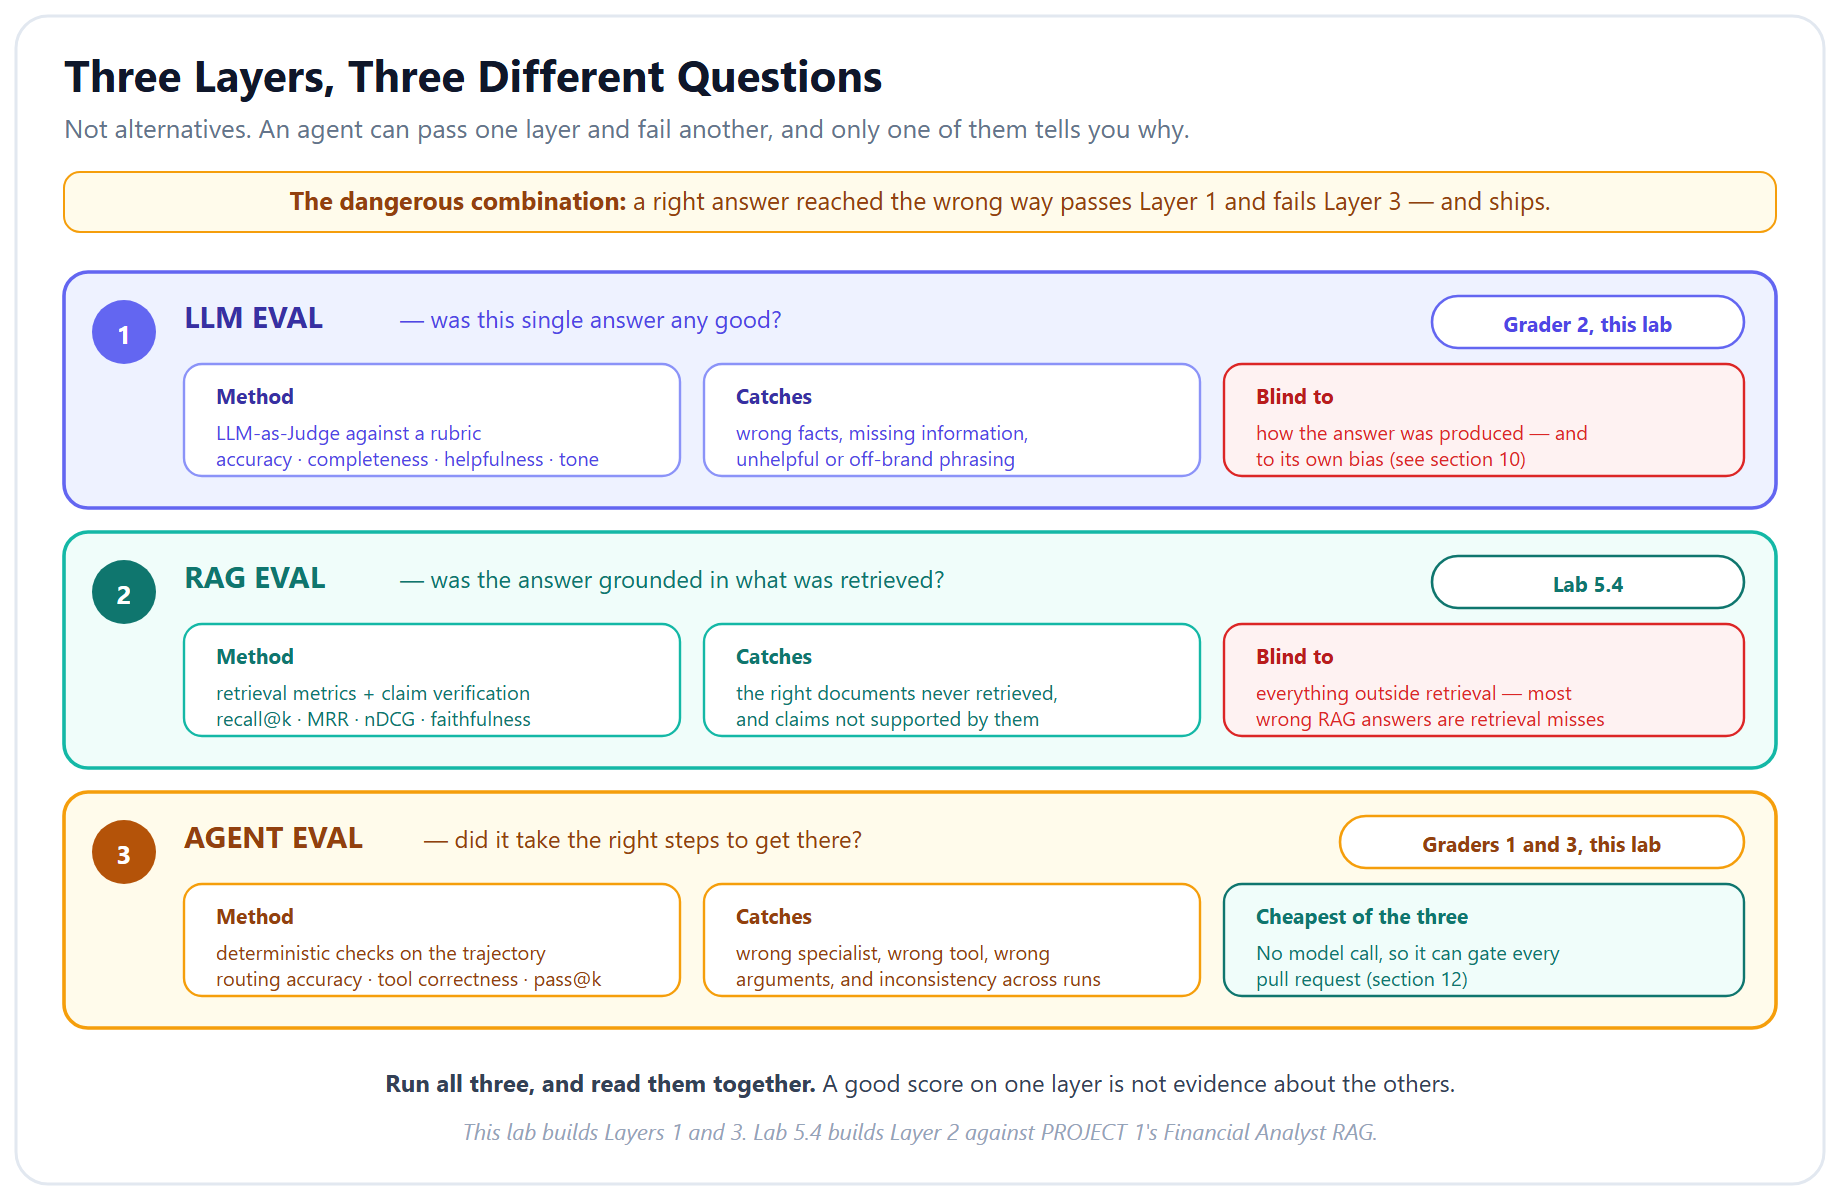

**Figure — Three layers, three different questions.** Layer 1 asks whether a single answer was good, Layer 2 whether it was grounded in what was retrieved, and Layer 3 whether the agent took the right *steps* to get there. They are not alternatives — an agent can pass Layer 1 while failing Layer 3, which is precisely the case that reaches production and then behaves unpredictably.

## 2. The System Under Test

The next cell is one `import`.

**PROJECT 2 is not rebuilt in this notebook.** It lives in `shopsmart_agent.py`, which ships
in the `Lab_5.3 Files` folder beside this lab, and it is Lab 3.1's system rather than a summary of it: PII redaction, the
FAISS policy index, ten tools, four ReAct specialists with their exact tool allocations and
prompts, the supervisor with its three escalation overrides, the routing table, the
checkpointer. Open the file — it is ordinary Python, and it is the thing this notebook measures.

**Two reasons it is a script and not twelve cells.**

*First, this lab is about evaluation.* Rebuilding an agent you already built in Module 3, before
the first grader appears, buries the subject under setup.

*Second — and this is the real one — a notebook copy of an agent is a copy that drifts.* Paste
a simplified router into a cell and call it "PROJECT 2's
supervisor pattern", and you get a different state class, different node names, no tools, no
retriever, and a classification schema with one field instead of five. That measures something
nobody has built or shipped. Instead, **every function in `shopsmart_agent.py` was AST-diffed
against Lab 3.1's notebook** — 17 functions checked, 4 documented deviations, listed below.

**Why the full system matters here.** An evaluation of a reduced system tells you about the
reduced system. Strip the tools and you cannot measure whether the agent looks anything up.
Strip the retriever and a policy failure is indistinguishable from a reasoning failure. Strip
PII redaction and you grade the agent on text it will never see in production. Every
simplification buys attribution and sells validity, and this lab has chosen validity.

**The complete list of deviations from Lab 3.1 — there are two, and both are forced.**

1. **`interrupt()` is not called.** Lab 3.1's escalation node suspends the graph so a human
   manager can review. An eval suite cannot pause twenty-four times. The node keeps its name
   and builds the same payload from the same escalation reasons; it returns it instead of
   suspending on it.
2. **Progress prints are gated behind `VERBOSE_AGENT`.** Lab 3.1 prints a line from every node,
   which is right for one ticket and unreadable across twenty-four. Set `VERBOSE_AGENT = True`
   in the module to watch a single run.

That is the whole list — the diff found no *other* difference.

**Where the taxonomy comes from.** The six categories are not a taxonomy this lab chose. They
are the categories `tickets.json` is *labelled* with, and the same six in Lab 3.1's
`TicketClassification`. That matters: routing accuracy is only meaningful against labels
somebody else assigned. A test set you wrote yourself, for an agent you wrote yourself,
measures how consistent you were — not how good the agent is.

| | Lab 2.3 | Lab 3.1 — PROJECT 2 | **Here** |
|---|---|---|---|
| Categories | 4 + spam | **6** | **the same 6, from the data's labels** |
| Data | 5 orders, inline | 5 files | **the same 5 files** |
| Specialists | 4 prompt handlers | 4 ReAct agents + quick-answer + escalation | **the same** |
| Tools | none | 10 | **the same 10** |
| Policy RAG | none | FAISS, k=3 | **the same index** |
| PII redaction | none | yes | **yes** |
| HITL | none | `interrupt()` | payload returned, not suspended |

> **A note on cost and time.** This suite runs a real multi-agent system twenty-four times.
> Each case is a supervisor call plus a ReAct loop that may call several tools, so expect
> minutes rather than seconds, and a bill rather than nothing. That is the honest price of
> evaluating what you actually ship — and section 11's CI split exists precisely so you do not
> pay it on every push.

In [ ]:
# --- The system under test: PROJECT 2, imported rather than rebuilt ---
# `shopsmart_agent.py` ships with this lab. It IS Lab 3.1's system - the same PII redaction,
# FAISS policy index, ten tools, four ReAct specialists, supervisor and routing table. Open it
# and read it; it is ordinary Python, and it is the thing this notebook measures.
#
# Importing it rather than pasting it is the point. A notebook copy of an agent is a copy that
# drifts, and an evaluation of a drifted copy tells you nothing about what you ship. This is
# also the shape the CI gate in section 11 assumes: `from shopsmart_agent import process_ticket`.
#
# Importing runs the FAISS index build, so the API-key cell above must have run first.

import sys
from typing import get_args


def find_shopsmart_module():
    """Return the folder holding `shopsmart_agent.py`.

    Colab users upload the "Lab_5.3 Files" folder next to the notebook; local users may run
    from the lab directory or one level above it. Same search order the data loader uses.

    Returns:
        An absolute path to the folder containing the module.

    Raises:
        FileNotFoundError: if none of the candidate locations contain it.
    """
    for candidate_folder in (".", "Lab_5.3 Files", "..", "../Lab_5.3 Files"):
        if os.path.exists(os.path.join(candidate_folder, "shopsmart_agent.py")):
            return os.path.abspath(candidate_folder)
    raise FileNotFoundError(
        "Could not find 'shopsmart_agent.py'. On Colab, upload the 'Lab_5.3 Files' folder "
        "next to this notebook - the module ships inside it.")


sys.path.insert(0, find_shopsmart_module())

from shopsmart_agent import (
    # the system under test
    process_ticket, compiled_agent, describe,
    # the data it runs on - the same five PROJECT 2 files, loaded once, in the module
    TICKETS, TICKET_CATEGORIES, CUSTOMERS_DB, ORDERS_DB, PRODUCTS_DB,
    customers_raw, orders_raw, products_raw, POLICY_SECTIONS,
    # pieces the graders reach for
    redact_pii, TOOL_REGISTRY, TicketClassification,
)

for fact in describe():
    print(fact)

## 3. Build the Labelled Test Dataset

Every eval suite lives or dies on one question: **where did the labels come from?**

If you write the test cases for an agent you also wrote, the suite measures how consistent you
were with yourself. It will pass. It will keep passing while the agent gets worse in ways you
did not think to encode.

`tickets.json` solves that for us. It ships 100 real support messages, each already carrying a
`category` and a `priority` assigned when the dataset was built — before this lab existed and
without reference to the agent under test. Those labels are the ground truth.

So the next cell **generates** the dataset rather than declaring it:

| Field | Where it comes from |
|---|---|
| `query` | the ticket's own text, verbatim — including the PII Module 6's guardrails lab will strip |
| `expected_category` | the ticket's shipped `category` label |
| `expected_priority` | the ticket's shipped `priority` label |
| `must_contain` | derived from the records the ticket references — the order's status, the product's price, the policy's remedy |
| `ideal` | a one-line summary built from those same records |

**24 cases, 4 per category.** Balanced rather than proportional: the corpus is 39% order_status
and 6% technical, so a proportional sample would let an agent that is excellent at order status
and hopeless at technical still score around 90%.

> **A caveat you should carry into your own work.** These labels are not sacred either. Look at
> `TKT-00010` — *"The website won't accept my payment"* — labelled `technical`. A reasonable
> person would call it `billing`. When your agent "fails" a case, the first thing to check is
> whether the label is right. Section 10 makes the same argument about the judge.

In [ ]:
# --- The labelled test dataset, built FROM the data rather than written by hand ---
# tickets.json ships 100 real support messages, each already carrying a `category` and a
# `priority`. Those labels are the ground truth: we did not assign them, which is the whole
# point of a golden dataset.
#
# Two deliberate choices, both worth arguing about before you copy this pattern:
#
#   1. BALANCED, NOT PROPORTIONAL. The corpus is 39% order_status and 6% technical. Sampling
#      proportionally would let a router that is excellent at order_status and hopeless at
#      technical still score ~90%. We take the SAME number of cases per category, so every
#      category can fail the suite on its own.
#   2. DETERMINISTIC. The sample is the first N of each category in file order - no shuffling,
#      no random seed to forget. Re-running this notebook evaluates the same cases.

CASES_PER_CATEGORY = 4

# The expected content for each category, expressed as a rule over the ticket's own records.
# Writing `must_contain` by hand is how a golden dataset quietly becomes a test of the author's
# memory; deriving it from the data keeps it a test of the agent.
STATUS_KEYWORDS = {"delivered": "delivered", "in_transit": "transit",
                   "processing": "processing", "cancelled": "cancelled"}

# Every ticket in this corpus opens with the same greeting: "Hi, I'm <Name>. My email is
# <address>." That boilerplate is PII, and it is also a TRAP for any keyword matcher: the word
# "email" appears in all 100 tickets, so a rule that looks for it fires on the greeting rather
# than on the problem. Strip the greeting first, and match only the sentence that describes the
# actual issue. Skipping that strip is a real bug - it grades a payment
# problem against the spam-folder remedy - and it is the reason the tests below exist.
# NOTE the \S+ rather than [^.]*: the address itself contains dots, so a
# "everything up to the next dot" pattern stops INSIDE "r.wilson@email.com" and
# leaves the rest of the address in the text. Measured: that version stripped
# cleanly in 0 of 100 tickets. \S+ is greedy and backtracks to the real full stop.
GREETING_PATTERN = re.compile(r"^\s*Hi,\s*I'm[^.]*\.\s*My email is\s+\S+\.\s*", re.IGNORECASE)


def strip_greeting(ticket_text):
    """Return the ticket text with the standard name-and-email greeting removed.

    Args:
        ticket_text: the raw ticket text, greeting included.

    Returns:
        Just the sentence(s) describing the problem.
    """
    return GREETING_PATTERN.sub("", ticket_text).strip()


# The remedies the Technical Support policy section prescribes, keyed by the words a customer
# uses to describe the problem. Every expected term below appears verbatim in policies.md.
# The triggers are deliberately specific: no bare "email", because that is a greeting word here.
TECHNICAL_REMEDIES = [
    (["password"], ["password", "reset"],
     "Self-service password reset via Forgot Password"),
    (["log in", "login", "locked", "account access"], ["verification", "unlock"],
     "Support can unlock the account after identity verification"),
    (["payment", "website", "site", "browser"], ["payment method", "cache"],
     "Try an alternative payment method and clear the browser cache"),
    (["confirmation email", "receiving order confirmation", "not receiving"],
     ["spam", "email address"],
     "Check the spam folder and verify the email address on file"),
]


def match_technical_remedy(ticket_text):
    """Return the (must_contain, ideal) pair the technical policy prescribes for this ticket.

    Args:
        ticket_text: the raw customer message, greeting included.

    Returns:
        A (must_contain, ideal) pair drawn from the Technical Support policy section.

    Raises:
        AssertionError: if no remedy matches. That is deliberate - silently falling back to a
        generic expectation is how a golden dataset starts passing cases it never checked.
    """
    problem = strip_greeting(ticket_text).lower()
    for trigger_words, expected_terms, ideal_answer in TECHNICAL_REMEDIES:
        if any(word in problem for word in trigger_words):
            return (expected_terms, ideal_answer)
    raise AssertionError(
        f"No technical remedy in policies.md covers this ticket: {problem!r}. "
        f"Either the policy needs a new section, or this ticket is mislabelled.")


# Prove the matcher reads the PROBLEM and not the greeting, before any case depends on it.
technical_tickets = [ticket for ticket in TICKETS if ticket["category"] == "technical"]
# Prove the strip itself, across the WHOLE corpus - a partial strip is invisible
# until it silently changes what a keyword rule matches.
unstripped = [ticket["ticket_id"] for ticket in TICKETS
              if "@" in strip_greeting(ticket["text"])]
print(f"tickets still carrying an email address after stripping: "
      f"{len(unstripped)}/{len(TICKETS)}")
print()
print("Technical-remedy matching, greeting stripped:")
for ticket in technical_tickets:
    terms, _ideal = match_technical_remedy(ticket["text"])
    print(f"  {ticket['ticket_id']}  {strip_greeting(ticket['text'])[:46]:<48} -> {terms}")
matched_remedies = {tuple(match_technical_remedy(t["text"])[0]) for t in technical_tickets}
print(f"\n{len(matched_remedies)} distinct remedies matched across "
      f"{len(technical_tickets)} technical tickets - if that were 1, the matcher would be "
      f"reading the greeting.")


def build_expected_content(ticket):
    """Derive what a correct answer to this ticket must contain, from the records it references.

    Args:
        ticket: one ticket dict from tickets.json.

    Returns:
        A (must_contain, ideal) pair. `must_contain` holds substrings a grounded answer has to
        quote; `ideal` is a one-line summary for the LLM judge to compare against.
    """
    order_match = re.search(r"ORD-\d{5}", ticket["text"])
    order = ORDERS_DB.get(order_match.group()) if order_match else None
    named_products = [product for product in products_raw
                      if product["name"].lower() in ticket["text"].lower()]

    if ticket["category"] == "product_inquiry" and named_products:
        product = named_products[0]
        return ([product["name"], str(product["price"])],
                f"{product['name']} costs ${product['price']} and is "
                f"{product['stock_status'].replace('_', ' ')}")

    if ticket["category"] == "technical":
        # A technical ticket references no order and no product, so there is nothing in the
        # ORDER data to ground it against. Its ground truth lives in the OTHER pre-provided
        # file: the Technical Support section of policies.md. Match the specific remedy that
        # section prescribes for the problem the customer describes.
        return match_technical_remedy(ticket["text"])

    if order is None:
        return (["ShopSmart"], "A helpful, policy-grounded answer with no order to quote")

    order_id = order["order_id"]
    if ticket["category"] == "order_status":
        return ([order_id, STATUS_KEYWORDS[order["status"]]],
                f"Order {order_id} is {order['status']}, estimated delivery "
                f"{order['estimated_delivery'][:10]}")
    if ticket["category"] == "returns":
        return ([order_id, "30"],
                f"Order {order_id} is within the 30-day return window; damaged or wrong items "
                f"are refunded in full including return shipping")
    if ticket["category"] == "billing":
        return ([order_id, str(order["total"])],
                f"Order {order_id} totals ${order['total']}; double charges are resolved "
                f"within 24 hours")
    # escalation
    return ([order_id, "escalat"],
            f"Acknowledge the complaint about {order_id} and escalate it for manager review")


# The reference trajectory: which tools a correct handling of this ticket would call.
#
# This is what makes Grader 3 a trajectory evaluator rather than a keyword search. It is
# derived from PROJECT 2's OWN routing table and tool allocations - read `route_ticket` and
# the four `create_agent` calls above and you can check every line of it.
#
# Two of these deserve to be argued with, which is the point:
#
#   - `order_status` WITH an order ID expects `quick_answer_lookup` and no model tools at
#     all, because PROJECT 2 short-circuits that case deterministically. An agent that calls
#     `lookup_order` there is not wrong, it is just not what this system does.
#   - `technical` expects NOTHING, because PROJECT 2 has no technical specialist - the
#     routing table sends technical tickets to the order specialist. That is a real gap in
#     the system, not an omission here, and section 7c is where the suite reports it.

def expected_tool_trajectory(ticket):
    """Return the tool calls a correct handling of this ticket should produce.

    Args:
        ticket: one ticket dict from tickets.json.

    Returns:
        A list of tool names, in no particular order - Grader 3 compares sets, because
        PROJECT 2's specialists are free to choose their own order.
    """
    category = ticket["category"]
    has_order_id = bool(re.search(r"ORD-\d{5}", ticket["text"]))

    if category == "order_status":
        # route_ticket() sends these to quick_answer when an order ID is present.
        return ["quick_answer_lookup"] if has_order_id else ["search_orders_by_customer"]
    if category == "returns":
        return ["lookup_order", "check_return_eligibility"]
    if category == "billing":
        return ["check_billing_status"]
    if category == "product_inquiry":
        return ["search_products"]
    if category == "technical":
        return []
    return ["escalation_hitl"]


TEST_DATASET = []
cases_taken = {category: 0 for category in TICKET_CATEGORIES}
for ticket in TICKETS:
    category = ticket["category"]
    if cases_taken[category] >= CASES_PER_CATEGORY:
        continue
    must_contain, ideal = build_expected_content(ticket)
    TEST_DATASET.append({
        "id": ticket["ticket_id"],
        "query": ticket["text"],
        "expected_category": category,          # the label that SHIPPED with the data
        "expected_priority": ticket["priority"],
        "customer_id": ticket["customer_id"],
        "customer_tier": CUSTOMERS_DB[ticket["customer_id"]]["tier"],
        "expected_tools": expected_tool_trajectory(ticket),
        "must_contain": must_contain,
        "ideal": ideal,
    })
    cases_taken[category] += 1

TEST_DATASET.sort(key=lambda case: (case["expected_category"], case["id"]))

print(f"Test dataset: {len(TEST_DATASET)} cases, {CASES_PER_CATEGORY} per category")
for category in TICKET_CATEGORIES:
    count = sum(1 for case in TEST_DATASET if case["expected_category"] == category)
    print(f"  {category:<16} {count} cases")
print()
print("Two sample cases, with the expectations derived from their own records:")
for case in (TEST_DATASET[0], TEST_DATASET[-1]):
    print(f"\n  {case['id']} -> {case['expected_category']} ({case['expected_priority']})")
    print(f"    query        : {case['query'][:96]}")
    print(f"    tier         : {case['customer_tier']}")
    print(f"    must_contain : {case['must_contain']}")
    print(f"    expected_tools: {case['expected_tools']}")
    print(f"    ideal        : {case['ideal'][:96]}")

In [ ]:
# --- Sanity Test ---
# One ticket through the REAL graph before spending money on twenty-four. Watch the tool
# calls: if this case answers without calling a tool, the specialists are not wired up and
# nothing measured below will mean anything.
sanity_case = TEST_DATASET[0]
sanity_result = process_ticket(sanity_case)

print(f"Case       : {sanity_case['id']}  ({sanity_case['customer_tier']} customer)")
print(f"Query      : {sanity_case['query'][:100]}")
print(f"Redacted   : {sanity_result['redacted_text'][:100]}")
print()
print(f"Expected   : {sanity_case['expected_category']} / {sanity_case['expected_priority']}")
print(f"Classified : {sanity_result['category']} / {sanity_result['priority']}  "
      f"{'MATCH' if sanity_result['category'] == sanity_case['expected_category'] else 'MISMATCH'}")
print(f"Confidence : {sanity_result['classification_confidence']:.2f}   "
      f"escalated={sanity_result.get('needs_escalation')}")
print()
print(f"Tools used : {sanity_result.get('tools_used', [])}")
print(f"Expected   : {sanity_case['expected_tools']}")
print()
print(f"Response   : {sanity_result['final_response'][:260]}...")

## 4. Grader 1 — Routing Accuracy (Deterministic)

Does the agent route to the **correct category**? This is a hard metric — either right or wrong. No LLM judgment needed.

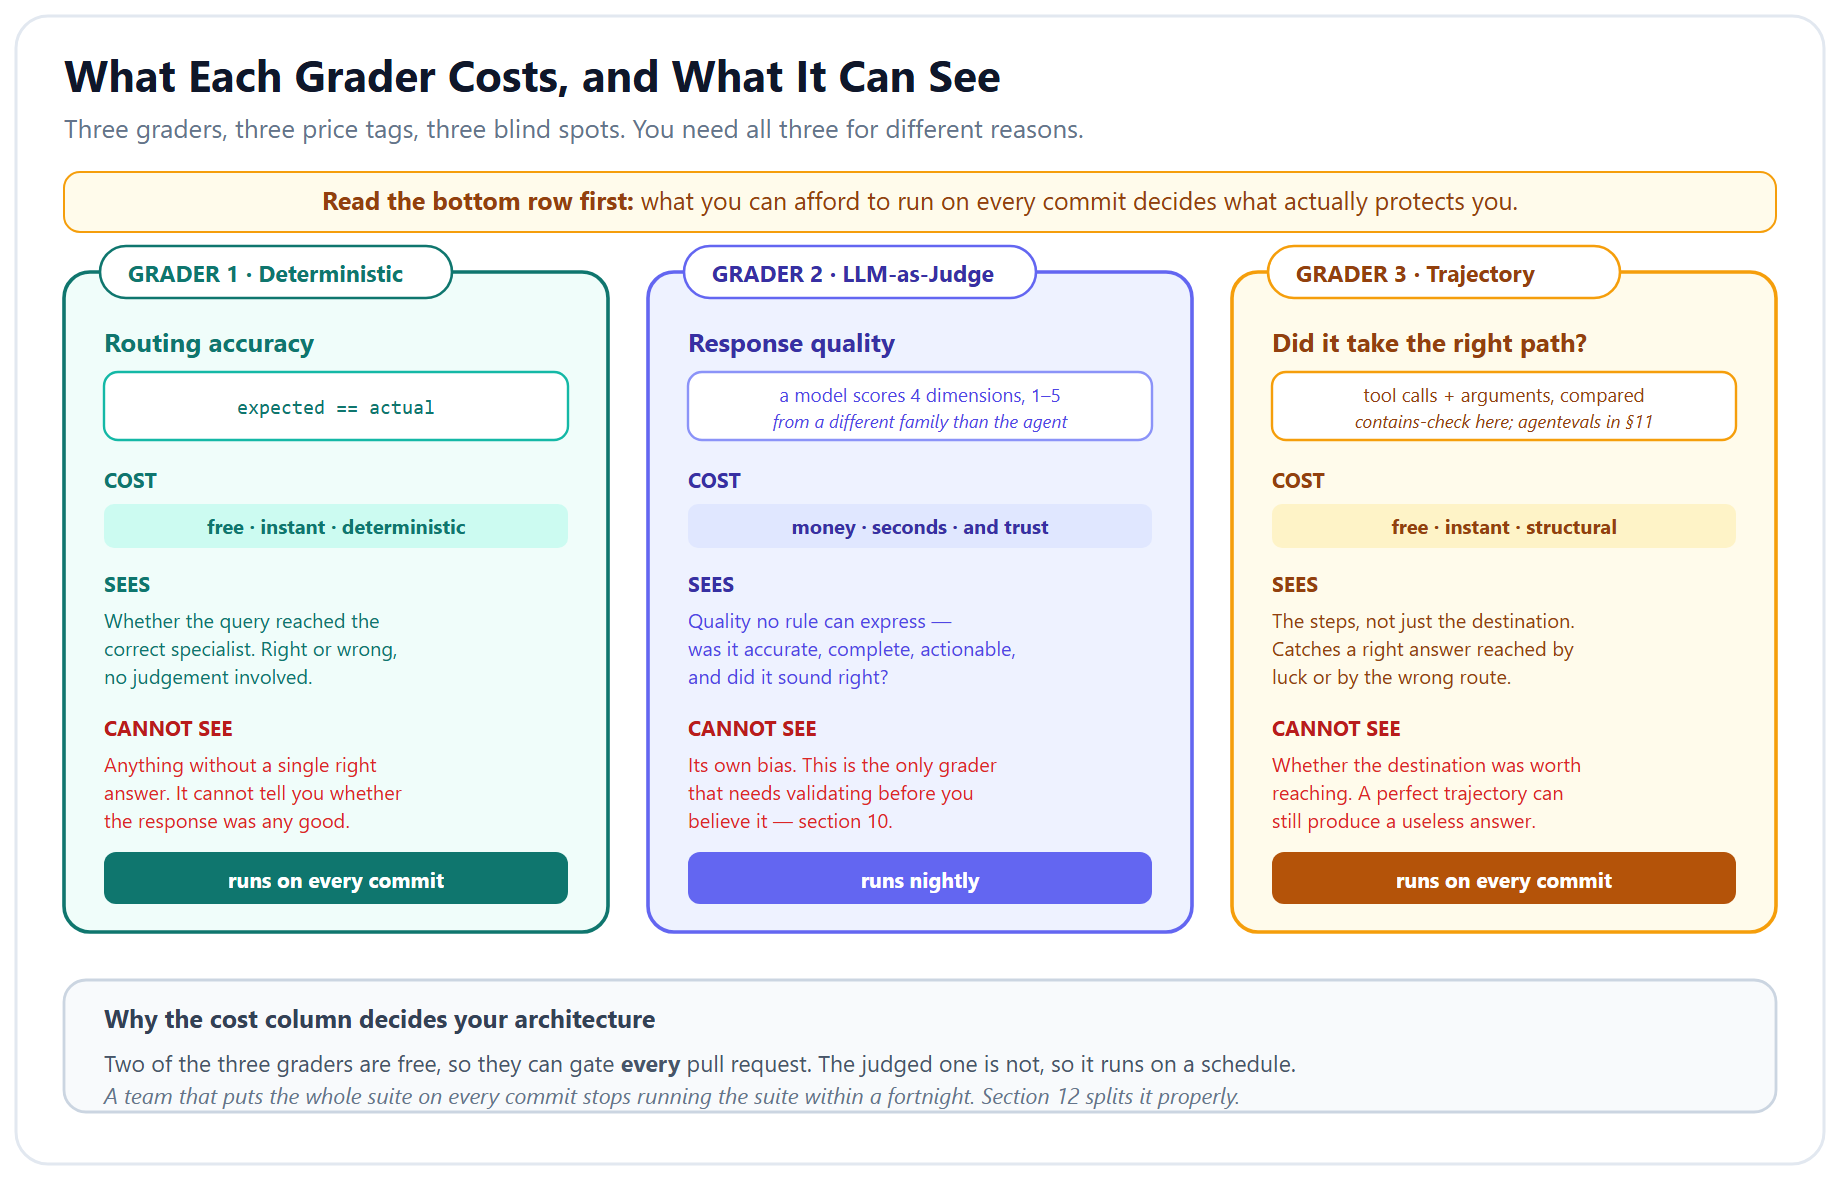

**Figure — What each grader costs and what it can see.** Deterministic graders are free, instant and completely certain — but only about things with a right answer. LLM judges see quality no rule can express, and cost money, latency and trust. Trajectory graders see the *path*, which is the only layer that catches an agent that reached the right answer the wrong way. Read the bottom row before deciding what runs on every commit.

In [ ]:
# --- Grader 1: Routing Accuracy ---
def evaluate_routing(expected_category: str, actual_category: str) -> bool:
    """Exact match: did the agent route to the correct category?"""
    return expected_category == actual_category

print("Grader 1 defined: evaluate_routing (exact match)")

In [ ]:
# --- Run Grader 1 on every case in the dataset ---
print("Running Grader 1: Routing Accuracy")
print("=" * 60)

routing_results = []
for test_case in TEST_DATASET:
    result = process_ticket(test_case)
    correct = evaluate_routing(test_case["expected_category"], result["category"])
    routing_results.append({
        "id": test_case["id"], "query": test_case["query"][:50],
        "expected": test_case["expected_category"], "actual": result["category"],
        "correct": correct, "response": result["final_response"],
        # Everything the supervisor decided, not just the category - section 7c grades these.
        "priority": result["priority"],
        "confidence": result["classification_confidence"],
        "escalated": result.get("needs_escalation", False),
        "tools_used": result.get("tools_used", []),
    })
    status = "\u2705" if correct else "\u274c"
    print(f"{status} {test_case['id']}: expected={test_case['expected_category']}, actual={result['category']}")

accuracy = sum(1 for routing_record in routing_results if routing_record["correct"]) / len(routing_results) * 100
print(f"\nOverall routing accuracy: {accuracy:.0f}%")

## 5. Grader 2 — Response Quality (LLM-as-Judge)

An LLM scores the response on **4 dimensions** (1-5 each): accuracy, completeness, helpfulness and tone. This extends the judge pattern from **Lab 5.2** — including its rule about model families, which section 10 turns into a standing one.

In [ ]:
# --- Grader 2: LLM-as-Judge Response Quality ---
quality_judge_prompt = ChatPromptTemplate.from_template(
    """You are an expert evaluator for ShopSmart customer support responses.

Score this response on 4 dimensions (1-5 each):
1. **Accuracy**: Are the facts correct? (order status, prices, policy details)
2. **Completeness**: Does it address ALL aspects of the query?
3. **Helpfulness**: Is it actionable? Does it tell the customer what to do next?
4. **Tone**: Professional, empathetic, ShopSmart brand voice?

Customer Query: {query}
Agent Response: {response}
Expected Info: {ideal}

Return ONLY a JSON object: {{"accuracy": X, "completeness": Y, "helpfulness": Z, "tone": W}}""")

# judge_model is claude-haiku-4-5 — a DIFFERENT family from the gpt-4.1-mini system under
# test. Section 10 explains why this matters more than any other line in the notebook.
quality_judge_chain = quality_judge_prompt | judge_model | StrOutputParser()

QUALITY_DIMENSIONS = ["accuracy", "completeness", "helpfulness", "tone"]


def evaluate_quality(query: str, response: str, ideal: str) -> dict | None:
    """Score one response with the cross-family LLM-as-Judge across four dimensions.

    Args:
        query: the customer query that was asked.
        response: the agent output being graded.
        ideal: a short summary of the information a correct answer should contain.

    Returns:
        A dict with the four dimension scores plus `total` out of 20, or None if the judge
        call failed, its output would not parse, or it omitted a dimension.

        Returning None matters twice over. A fallback that returns a fabricated 3/3/3/3 = 12/20
        on ANY failure lets a broken judge draw a flat, plausible dashboard rather than an
        error — and defaulting individual missing dimensions to 3 quietly completes a partial
        answer with invented numbers. A missing score must look missing.
    """
    try:
        judge_reply = quality_judge_chain.invoke(
            {"query": query, "response": response, "ideal": ideal}).strip()
        if judge_reply.startswith("```"):          # strip a ```json … ``` fence if present
            judge_reply = judge_reply.split("```")[1].replace("json", "").strip()
        scores = json.loads(judge_reply)
        missing = [dimension for dimension in QUALITY_DIMENSIONS if dimension not in scores]
        if missing:
            print(f"   ⚠️  judge omitted {missing} — row dropped rather than defaulted")
            return None
        scores["total"] = sum(scores[dimension] for dimension in QUALITY_DIMENSIONS)
        return scores
    except json.JSONDecodeError as parse_error:
        print(f"   ⚠️  judge returned unparseable output ({parse_error}) — row dropped")
        return None
    except Exception as call_error:
        print(f"   ⚠️  judge call failed ({type(call_error).__name__}) — row dropped")
        return None

print("Grader 2 defined: evaluate_quality (LLM-as-Judge, 4 dimensions)")

In [ ]:
# --- Test the Judge: Good vs Bad Response ---
# Both responses answer the SAME real question about a real order, so the only thing that
# differs is grounding. A judge that cannot separate these two is not worth running.
smoke_case = next(case for case in TEST_DATASET
                  if case["expected_category"] == "order_status")
smoke_order = ORDERS_DB[re.search(r"ORD-\d{5}", smoke_case["query"]).group()]

good_response = (f"Your order {smoke_order['order_id']} "
                 f"({smoke_order['items'][0]['name']}) is {smoke_order['status']}. "
                 f"The total was ${smoke_order['total']} and the tracking number is "
                 f"{smoke_order['tracking_number']}.")
bad_response = "I'm not sure about your order. Please try again later."

print("Judge Test: Good Response")
good_scores = evaluate_quality(smoke_case["query"], good_response, smoke_case["ideal"])
print(f"  Scores: {good_scores}")

print("\nJudge Test: Bad Response")
bad_scores = evaluate_quality(smoke_case["query"], bad_response, smoke_case["ideal"])
print(f"  Scores: {bad_scores}")
if good_scores is None or bad_scores is None:
    print("\n⚠️  One of the judge calls failed — fix that before trusting anything below.")
else:
    print(f"\nDelta: {good_scores['total'] - bad_scores['total']} points "
          f"(a judge that cannot separate these two is not worth running)")

In [ ]:
# --- Run Grader 2 on every case in the dataset ---
print("Running Grader 2: Response Quality (LLM-as-Judge)")
print("=" * 60)

# Escalated cases are EXCLUDED, not scored badly. PROJECT 2 hands them to a human manager,
# and on that path the answer IS the manager's text - here a fixed stub. Judging it would
# score SCRIPTED_MANAGER_NOTE rather than the agent, and averaging that into the totals would
# move every headline number for no reason. Where your system hands off to a human, your
# automated metrics stop applying: drop those rows and say how many you dropped.
ESCALATED_POSITIONS = {position for position, record in enumerate(routing_results)
                       if record["escalated"]}

quality_results = []
for position, routing_record in enumerate(routing_results):
    test_case = TEST_DATASET[position]
    if position in ESCALATED_POSITIONS:
        quality_results.append(None)                 # None is kept, so indices stay aligned
        print(f"{test_case['id']}: excluded - escalated to a human, the answer is not the agent's")
        continue
    scores = evaluate_quality(test_case["query"], routing_record["response"],
                              test_case["ideal"])
    quality_results.append(scores)                   # None is kept, so indices stay aligned
    if scores is None:
        print(f"{test_case['id']}: not scored (judge failed)")
        continue
    print(f"{test_case['id']}: acc={scores['accuracy']} comp={scores['completeness']} "
          f"help={scores['helpfulness']} tone={scores['tone']} total={scores['total']}/20")

scored_quality = [record for record in quality_results if record is not None]
# Guard the denominator. The whole point of returning None on a judge failure is that a
# broken judge must look broken — dividing by zero here would replace an honest "0 rows
# scored" with a traceback, and an empty run is exactly when you most need the message.
average_total = (sum(record["total"] for record in scored_quality) / len(scored_quality)
                 if scored_quality else float("nan"))
# Report the two kinds of missing row separately. "Excluded because a human handled it"
# and "missing because the judge broke" mean opposite things, and one number hides both.
judge_failure_count = sum(1 for position, record in enumerate(quality_results)
                          if record is None and position not in ESCALATED_POSITIONS)
print()
print(f"Average quality: {average_total:.1f}/20  "
      f"({len(scored_quality)}/{len(quality_results)} rows scored | "
      f"{len(ESCALATED_POSITIONS)} escalated, excluded | "
      f"{judge_failure_count} judge failures)")

## 6. Grader 3 — Trajectory / Tool Correctness

Agent eval goes beyond response quality — did the agent take the **correct steps**? We check whether the response contains expected keywords (proxy for correct tool usage in our simplified agent).

In [ ]:
# --- Grader 3: Trajectory / Contains-Check ---
def evaluate_trajectory(response: str, must_contain: list) -> dict:
    """Check if the response contains expected keywords (proxy for tool correctness)."""
    response_lower = response.lower()
    found = [keyword for keyword in must_contain if keyword.lower() in response_lower]
    missing = [keyword for keyword in must_contain if keyword.lower() not in response_lower]

    precision = len(found) / len(must_contain) if must_contain else 1.0
    recall = len(found) / len(must_contain) if must_contain else 1.0
    f1_score = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    return {
        "found": found, "missing": missing,
        "precision": precision, "recall": recall, "f1": f1_score,
        "pass": len(missing) == 0
    }

print("Grader 3 defined: evaluate_trajectory (keyword contains-check, precision/recall/F1)")

**Why does the formula of precision and recall same in this usecase? is this expected ?**
In this specific implementation, yes, it is expected that precision and recall are the same.

Here is why:

The Denominator: In standard IR, Precision is `Found / Total Predicted` and Recall is `Found / Total Actual`.

This Use Case: In your `evaluate_trajectory function`, the `must_contain` list represents both the 'Actual' (what should be there) and the 'Predicted' (the set of tokens we are checking for).

The Math: Since the code uses `len(must_contain`) as the denominator for both variables, they will always be identical.


When would they differ? If your agent actually outputted a specific list of tags/keywords and you compared that output list against the ground truth list, they would differ:

- Precision would be `Correct_Keywords / Total_Keywords_Agent_Outputted`.

- Recall would be `Correct_Keywords / Total_Keywords_In_Ground_Truth`.


In this 'contains-check' proxy, you are simply measuring the percentage of required information present in the string.

In [ ]:
# --- Run Grader 3 on every case in the dataset ---
print("Running Grader 3: Trajectory / Contains-Check")
print("=" * 60)

trajectory_results = []
for position, routing_record in enumerate(routing_results):
    test_case = TEST_DATASET[position]
    if position in ESCALATED_POSITIONS:
        trajectory_results.append(None)              # excluded for the same reason as Grader 2
        print(f"-- {test_case['id']}: excluded - escalated to a human")
        continue
    trajectory = evaluate_trajectory(routing_record["response"], test_case["must_contain"])
    trajectory_results.append(trajectory)
    status = "\u2705" if trajectory["pass"] else "\u274c"
    print(f"{status} {test_case['id']}: F1={trajectory['f1']:.2f} | found={trajectory['found']} | missing={trajectory['missing']}")

scored_trajectories = [record for record in trajectory_results if record is not None]
average_f1 = (sum(record["f1"] for record in scored_trajectories) / len(scored_trajectories)
              if scored_trajectories else float("nan"))
pass_rate = (sum(1 for record in scored_trajectories if record["pass"])
             / len(scored_trajectories) * 100 if scored_trajectories else float("nan"))
print()
print(f"Average F1: {average_f1:.2f} | Pass rate: {pass_rate:.0f}%  "
      f"({len(scored_trajectories)}/{len(trajectory_results)} scored, "
      f"{len(ESCALATED_POSITIONS)} escalated and excluded)")

### 6b. Two graders called "trajectory", and only one of them deserves the name

*Read this alongside Grader 3 — it is the difference between the instrument you just built and
the one section 7c builds.*

The Grader 3 you have just written asks: **are the required strings present in the answer?**
That is a useful proxy for grounding. It is deterministic, free and instant. It is also blind
to the thing a trajectory evaluator exists to measure.

A trajectory is the ordered record of what the agent *did* — which tools it called, in what
order, with what arguments. Two failures a contains-check scores identically:

| What went wrong | What a contains-check sees | What it actually is |
|---|---|---|
| Called `search_products` instead of `lookup_order` | a missing string | **the wrong tool** — a routing bug |
| Called `lookup_order` with the wrong order ID | a missing string | **the right tool, wrong arguments** — a parsing bug |

Those are different bugs in different code, and separating them is usually the whole diagnosis.

**In this lab you can have both, and you should.** The system under test is PROJECT 2 running
for real: four ReAct specialists, ten tools, a FAISS policy index. Every tool call is recorded
in `tools_used` as it happens, so section 7c compares those recorded calls against a reference
trajectory derived from PROJECT 2's own routing table.

Keep the contains-check anyway. The two measure different things and disagree usefully:

| | Contains-check (Grader 3) | Tool trajectory (section 7c) |
|---|---|---|
| Asks | did the answer *state* the fact? | did the agent *look the fact up*? |
| Catches | ungrounded prose, omitted detail | wrong tool, tool never called, wasted calls |
| Misses | a right answer phrased differently | a perfect trajectory summarised badly |
| Costs | nothing | nothing — the calls were already recorded |

An agent can call every correct tool and then write a useless answer. It can also write a
perfect answer having called nothing, by reciting something plausible. **You need both numbers
to tell those two apart**, and reporting either one alone is how a dashboard ends up
describing a system nobody has actually checked.

**What is still missing.** Neither grader checks tool *arguments*, and neither checks *order*.
`agentevals` does both — strict, unordered and args-ignored match modes, plus graph-trajectory
evaluators that read a LangGraph thread directly. That is the next thing to reach for once
argument correctness starts mattering to you.

## 7. Run the Complete Suite

Combine all 3 graders into a single results table.

In [ ]:
# --- Combined Results Table ---
print("FULL EVAL SUITE RESULTS")
print("=" * 90)
print(f"{'ID':<10} {'Category':<16} {'Routing':>7} {'Quality':>9} "
      f"{'Traj F1':>8} {'Traj Pass':>10}")
print("-" * 90)

for position in range(len(TEST_DATASET)):
    test_case = TEST_DATASET[position]
    routing_passed = "\u2705" if routing_results[position]["correct"] else "\u274c"
    quality = (quality_results[position]["total"]
               if quality_results[position] is not None else "--")
    f1_score = (trajectory_results[position]["f1"]
                if trajectory_results[position] is not None else float("nan"))
    trajectory_passed = ("--" if trajectory_results[position] is None
                         else "\u2705" if trajectory_results[position]["pass"] else "\u274c")
    print(f"{test_case['id']:<10} {test_case['expected_category']:<16} {routing_passed:>6} "
          f"{str(quality):>6}/20 {f1_score:>8.2f} {trajectory_passed:>9}")

### 7b. Dashboard — Aggregate Metrics

In [ ]:
# --- Aggregate Metrics ---
# Read the categories off the dataset rather than repeating them. A hard-coded list here
# is how a category silently stops being evaluated when the taxonomy changes.
categories = TICKET_CATEGORIES

# Per-category routing accuracy
routing_by_category = {}
for category_name in categories:
    category_tests = [routing_record for position, routing_record in enumerate(routing_results) if TEST_DATASET[position]["expected_category"] == category_name]
    routing_by_category[category_name] = sum(1 for routing_record in category_tests if routing_record["correct"]) / len(category_tests) * 100 if category_tests else 0

# Per-category quality average
quality_by_category = {}
for category_name in categories:
    category_scores = [quality_results[position]["total"]
                  for position in range(len(TEST_DATASET))
                  if TEST_DATASET[position]["expected_category"] == category_name
                  and quality_results[position] is not None]
    quality_by_category[category_name] = sum(category_scores) / len(category_scores) if category_scores else 0

# Per-category trajectory F1
trajectory_by_category = {}
for category_name in categories:
    category_f1_scores = [trajectory_results[position]["f1"]
                          for position in range(len(TEST_DATASET))
                          if TEST_DATASET[position]["expected_category"] == category_name
                          and trajectory_results[position] is not None]
    trajectory_by_category[category_name] = sum(category_f1_scores) / len(category_f1_scores) if category_f1_scores else 0

print("Aggregate Metrics by Category")
print("=" * 60)
print(f"{'Category':<16} {'Routing':>9} {'Quality':>11} {'Traj F1':>9}")
print("-" * 60)
for category_name in categories:
    print(f"{category_name:<16} {routing_by_category[category_name]:>8.0f}%"
          f" {quality_by_category[category_name]:>7.1f}/20"
          f" {trajectory_by_category[category_name]:>9.2f}")

# Identify weakest (logic: prioritize lowest Routing, then lowest Traj F1, then lowest Quality)
weakest_category = min(categories, key=lambda category_name: (routing_by_category[category_name], trajectory_by_category[category_name], quality_by_category[category_name]))

print(f"\nWeakest category: {weakest_category}")
print(f"  Criteria: Routing {routing_by_category[weakest_category]:.0f}%, Traj F1 {trajectory_by_category[weakest_category]:.2f}, Quality {quality_by_category[weakest_category]:.1f}/20")

In [ ]:
# --- Matplotlib Dashboard ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top-left: Routing accuracy per category
# One colour per category, derived from the taxonomy rather than a fixed list — a
# hard-coded palette silently repeats colours when the number of categories changes.
category_colors = plt.get_cmap("tab10")(np.linspace(0, 0.9, len(categories)))
axes[0,0].bar(categories, [routing_by_category[category_name] for category_name in categories], color=category_colors)
axes[0,0].set_title('Routing Accuracy by Category')
axes[0,0].set_ylabel('Accuracy (%)')
axes[0,0].set_ylim(0, 110)
axes[0,0].axhline(y=80, color='red', linestyle='--', alpha=0.5, label='80% target')
axes[0,0].legend()
for position, value in enumerate([routing_by_category[category_name] for category_name in categories]):
    axes[0,0].text(position, value + 2, f'{value:.0f}%', ha='center')

# Top-right: Quality scores per dimension (average across all tests)
dimensions = ['accuracy', 'completeness', 'helpfulness', 'tone']
dimension_averages = [statistics.fmean([record[dimension] for record in quality_results
                                  if record is not None])
            for dimension in dimensions]
axes[0,1].bar(dimensions, dimension_averages, color=['#E91E63', '#00BCD4', '#FFC107', '#8BC34A'])
axes[0,1].set_title('Average Quality by Dimension')
axes[0,1].set_ylabel('Score (1-5)')
axes[0,1].set_ylim(0, 5.5)
for position, value in enumerate(dimension_averages):
    axes[0,1].text(position, value + 0.1, f'{value:.1f}', ha='center')

# Bottom-left: Trajectory F1 per category
axes[1,0].bar(categories, [trajectory_by_category[category_name] for category_name in categories], color=category_colors)
axes[1,0].set_title('Trajectory F1 by Category')
axes[1,0].set_ylabel('F1 Score')
axes[1,0].set_ylim(0, 1.1)
for position, value in enumerate([trajectory_by_category[category_name] for category_name in categories]):
    axes[1,0].text(position, value + 0.02, f'{value:.2f}', ha='center')

# Bottom-right: Overall pass rates
overall_routing = sum(1 for routing_record in routing_results if routing_record['correct']) / len(routing_results) * 100
overall_quality = statistics.fmean([record['total'] for record in quality_results
                                    if record is not None]) / 20 * 100
overall_traj = (sum(1 for record in trajectory_results
                    if record is not None and record['pass'])
                / max(1, sum(1 for record in trajectory_results if record is not None)) * 100)
bars = axes[1,1].bar(['Routing', 'Quality', 'Trajectory'],
                      [overall_routing, overall_quality, overall_traj],
                      color=['#2196F3', '#E91E63', '#4CAF50'])
axes[1,1].set_title('Overall Pass Rates')
axes[1,1].set_ylabel('Pass Rate (%)')
axes[1,1].set_ylim(0, 110)
for bar_patch, value in zip(bars, [overall_routing, overall_quality, overall_traj]):
    axes[1,1].text(bar_patch.get_x() + bar_patch.get_width() / 2, value + 2,
                   f'{value:.0f}%', ha='center')

plt.suptitle('ShopSmart Agent Eval Dashboard (3-Layer)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 7c. Grading everything the supervisor decides — not just the category

Look again at `TicketClassification`. Every call to the supervisor produces **five** outputs:

| Field | What it drives | Graded so far? |
|---|---|---|
| `category` | which specialist gets the ticket | ✅ Grader 1 |
| `priority` | queue order, SLA, and the platinum escalation override | ❌ |
| `confidence` | escalation below 0.6 — a human gets involved | ❌ |
| `requires_escalation` | whether a human gets involved at all | ❌ |
| `reasoning` | the audit trail a reviewer reads | ❌ |

Routing accuracy grades **one of five**. The other four decide who waits, who gets a human,
and what a manager sees — and `tickets.json` ships a `priority` label for all 100 tickets, so
one of them is free to measure.

**Confidence is the interesting one.** `supervisor_router` escalates any ticket whose
confidence is below 0.6. That rule is only sensible if confidence actually predicts
correctness. If the classifier is confidently wrong as often as it is confidently right, the
threshold is routing tickets to humans at random while looking principled.

This is measurable in one line: **compare mean confidence on the cases it got right against
mean confidence on the cases it got wrong.** If the gap is near zero, the number is decoration.
A model that says 0.95 on everything has told you nothing, and every downstream rule reading
that field inherits the emptiness.

**And the trajectory is now real.** The specialists are ReAct agents with ten tools between
them, so `tools_used` holds the tools they actually called. Grader 3 can compare that against
a reference trajectory instead of searching prose for substrings — which is the difference
between "the answer mentioned the tracking number" and "the agent looked the order up."

Watch two things in the table below:

1. **`technical` calls order-specialist tools.** PROJECT 2's routing table has no technical
   specialist — `route_ticket` sends technical tickets to `order_handler`. The suite finds
   that on its own. This is what an evaluation is *for*: it found a design gap in the system
   you built, without anybody writing a test that looked for it.
2. **Escalation overrides beat category routing.** A returns ticket that trips an escalation
   rule never reaches the returns specialist, so its trajectory is `escalation_queue` and not
   the returns tools. That is correct behaviour scoring as a trajectory miss — and deciding
   which of those two things to change is a judgement call, not a bug fix.

**A fifth thing worth grading: who gets a human.** `requires_escalation` pulls a person into the
loop, which is the most expensive judgement the supervisor makes. The ground truth for it is
asymmetric and the code below treats it that way:

- Every ticket **labelled** `escalation` must escalate. A miss there is a real failure — a
  customer asked for a manager and did not get one. That is recall, and it is scored.
- Escalations on **other** categories are not errors. The platinum rule and the 0.60 confidence
  rule are policy firing as designed. Those get counted and explained, never marked wrong —
  but each one is a person's time, so the count is a cost you should be able to defend.

**And one finding about the dataset rather than the agent.** `TicketClassification` allows a
`critical` priority and `supervisor_router` escalates on it — but the corpus contains **no
critical tickets at all**. The classifier can therefore emit a label the ground truth can never
match, and be marked wrong for a judgement nobody can check. That is a dataset problem, it
quietly costs you accuracy points, and the cell below prints it rather than letting it hide
inside a percentage. Either drop the label from the schema or get cases that use it.

---

### The best exercise in this lab uses a bug nobody planted

`shopsmart_agent.py` carries a **real defect, taken from Lab 3.1 unchanged**. The specialists
pick their answer out of the returned messages with:

```python
if hasattr(message, "content") and message.content and not hasattr(message, "tool_calls")
```

`hasattr(message, "tool_calls")` is **always `True` for an `AIMessage`** — the field exists even
when it holds an empty list. So the condition never accepts the agent's actual answer. Walking
the list in reverse, the first message that *does* satisfy it is the last `ToolMessage`, whose
content is raw tool JSON.

It is invisible in Lab 3.1 because `format_response_node` hands that JSON to a second model
which rewrites it into a perfectly readable email. The customer gets prose. The prose is
assembled from a database dump instead of from the specialist's reasoning.

**This is what an evaluation suite is for.** Nobody wrote a test looking for it; the metrics
just refused to add up. So:

1. Run the suite as it stands and write the three numbers down.
2. Set `USE_FIXED_RESPONSE_EXTRACTION = True` in `shopsmart_agent.py`.
3. Re-run sections 4–7 and put the two dashboards side by side.

That is the eval-driven improvement loop section 8 describes and never closes — run on a real
defect, in a real system, with a measured before and after. **Change one thing, re-run
everything, compare against the written baseline.** If the numbers barely move, that is a
result too: it means the formatter was compensating, and you have learned something about how
much of your quality score belongs to the last model in the chain rather than the agent.

In [ ]:
# --- Grade the other things the supervisor decided ---
# Everything below reads `routing_results`, which section 4 already populated. No extra model
# calls, no extra cost: these numbers were sitting in the state object the whole time.

def evaluate_priority(expected_priority, actual_priority):
    """Return True when the classifier's priority matches the shipped label.

    Args:
        expected_priority: the `priority` value tickets.json ships.
        actual_priority: what the supervisor decided.

    Returns:
        bool
    """
    return expected_priority == actual_priority


def evaluate_tool_trajectory(expected_tools, actual_tools):
    """Score a recorded tool trajectory against the reference one.

    Compares SETS, not sequences: PROJECT 2's specialists are free to choose their own
    order, so demanding an exact sequence would fail correct behaviour.

    Args:
        expected_tools: tool names a correct handling should call.
        actual_tools: tool names actually recorded in `tools_used`.

    Returns:
        A dict with precision, recall, f1 and the missing / unexpected tool names.
    """
    expected_set = set(expected_tools)
    # Drop the bookkeeping entries - they name the node, not a tool the model chose.
    actual_set = {name for name in actual_tools
                  if name not in {"supervisor_classifier", "order_specialist",
                                  "returns_specialist", "billing_specialist",
                                  "product_specialist", "response_formatter"}}

    if not expected_set and not actual_set:
        return {"precision": 1.0, "recall": 1.0, "f1": 1.0, "missing": [], "unexpected": []}

    matched = expected_set & actual_set
    precision = len(matched) / len(actual_set) if actual_set else 0.0
    recall = len(matched) / len(expected_set) if expected_set else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0
    return {"precision": precision, "recall": recall, "f1": f1,
            "missing": sorted(expected_set - actual_set),
            "unexpected": sorted(actual_set - expected_set)}


print("Grader 1b: Priority Accuracy")
print("=" * 78)
priority_correct = 0
for test_case, record in zip(TEST_DATASET, routing_results):
    matched = evaluate_priority(test_case["expected_priority"], record["priority"])
    priority_correct += matched
    mark = "✅" if matched else "❌"
    print(f"{mark} {test_case['id']}: expected={test_case['expected_priority']:<8} "
          f"actual={record['priority']}")
priority_accuracy = priority_correct / len(TEST_DATASET)
print(f"\nPriority accuracy: {priority_accuracy:.0%} "
      f"({priority_correct}/{len(TEST_DATASET)})")
print("Compare that with routing accuracy. If it is much lower, every SLA and queue-order")
print("decision downstream of this field is running on a coin flip.")

print()
print("Grader 1c: Is the confidence score worth anything?")
print("=" * 78)
confidence_when_right = [record["confidence"] for record in routing_results
                         if record["correct"]]
confidence_when_wrong = [record["confidence"] for record in routing_results
                         if not record["correct"]]

mean_right = statistics.mean(confidence_when_right) if confidence_when_right else float("nan")
mean_wrong = statistics.mean(confidence_when_wrong) if confidence_when_wrong else float("nan")

print(f"  mean confidence when CORRECT : {mean_right:.3f}  (n={len(confidence_when_right)})")
print(f"  mean confidence when WRONG   : {mean_wrong:.3f}  (n={len(confidence_when_wrong)})")

if confidence_when_wrong:
    separation = mean_right - mean_wrong
    print(f"  separation                   : {separation:+.3f}")
    print()
    if separation < 0.05:
        print("  READ THIS: the classifier is about as confident when it is wrong as when it")
        print("  is right. `supervisor_router` escalates everything below 0.60 - on this")
        print("  evidence that rule is sending tickets to humans at random. Either recalibrate")
        print("  the score or stop branching on it.")
    else:
        print("  The score separates right from wrong, so the 0.60 escalation threshold is")
        print("  doing real work. Check WHERE the threshold sits, not just that it separates.")
else:
    print("  Every case routed correctly, so there is nothing to compare against.")
    print("  A confidence score cannot be validated on a suite it never fails.")

below_threshold = [record for record in routing_results if record["confidence"] < 0.6]
print(f"\n  cases below the 0.60 escalation threshold: {len(below_threshold)}")
print(f"  of those, actually misrouted            : "
      f"{sum(1 for record in below_threshold if not record['correct'])}")

print()
print("Grader 3 (real): Tool Trajectory")
print("=" * 78)
print(f"{'ID':<12} {'Category':<16} {'F1':>5}  {'missing / unexpected'}")
trajectory_scores = []
for test_case, record in zip(TEST_DATASET, routing_results):
    score = evaluate_tool_trajectory(test_case["expected_tools"], record["tools_used"])
    trajectory_scores.append(score)
    detail = ""
    if score["missing"]:
        detail += f"missing={score['missing']} "
    if score["unexpected"]:
        detail += f"unexpected={score['unexpected']}"
    print(f"{test_case['id']:<12} {test_case['expected_category']:<16} "
          f"{score['f1']:>5.2f}  {detail}")

mean_trajectory_f1 = statistics.mean(score["f1"] for score in trajectory_scores)
print(f"\nMean tool-trajectory F1: {mean_trajectory_f1:.2f}")
print()
print("Per category - this is where the design gaps show up:")
for category in TICKET_CATEGORIES:
    category_scores = [score["f1"] for test_case, score in zip(TEST_DATASET, trajectory_scores)
                       if test_case["expected_category"] == category]
    if category_scores:
        print(f"  {category:<16} {statistics.mean(category_scores):>5.2f}")


print()
print("Grader 1d: The escalation decision - who gets a human")
print("=" * 78)
# `requires_escalation` decides whether a person is pulled into the loop. That is the most
# expensive judgement the supervisor makes, and until now nothing graded it.
#
# The ground truth is asymmetric, and it is worth being careful about why:
#   - Every ticket LABELLED `escalation` must escalate. That is recall, and a miss is a real
#     failure - a customer who asked for a manager and did not get one.
#   - Escalations on OTHER categories are not errors. `supervisor_router` escalates platinum
#     customers on high priority and anything under 0.60 confidence. Those are business rules
#     firing as designed, so they are counted and explained rather than scored as wrong.


def evaluate_escalation(expected_category, escalated):
    """Return True when a ticket labelled `escalation` actually escalated.

    Args:
        expected_category: the ticket's shipped category label.
        escalated: whether `needs_escalation` was set for this run.

    Returns:
        True if the required escalation happened, False if it was missed, None when the
        ticket was not an escalation ticket and the question does not apply.
    """
    if expected_category != "escalation":
        return None
    return bool(escalated)


escalation_labelled = [(case, record) for case, record in zip(TEST_DATASET, routing_results)
                       if case["expected_category"] == "escalation"]
escalation_caught = sum(1 for case, record in escalation_labelled
                        if evaluate_escalation(case["expected_category"], record["escalated"]))
if escalation_labelled:
    print(f"  escalation-labelled cases : {len(escalation_labelled)}")
    print(f"  correctly escalated       : {escalation_caught} "
          f"({escalation_caught / len(escalation_labelled):.0%} recall)")
    for case, record in escalation_labelled:
        mark = "✅" if record["escalated"] else "❌ MISSED - a customer asked for a manager"
        print(f"    {case['id']}  {mark}")

policy_escalations = [(case, record) for case, record in zip(TEST_DATASET, routing_results)
                      if record["escalated"] and case["expected_category"] != "escalation"]
print(f"\n  escalated by business rule rather than by label: {len(policy_escalations)}")
for case, record in policy_escalations:
    reasons = []
    if case["customer_tier"] == "platinum":
        reasons.append("platinum tier")
    if record["confidence"] < 0.6:
        reasons.append(f"confidence {record['confidence']:.2f} < 0.60")
    if record["priority"] in ("high", "critical"):
        reasons.append(f"{record['priority']} priority")
    print(f"    {case['id']} ({case['expected_category']}) - {'; '.join(reasons) or 'model flag'}")
print("  These are NOT errors. They are the policy in `supervisor_router` working. But every")
print("  one is a human's time, so the count is a cost you should be able to defend.")

print()
print("A label the data never uses")
print("=" * 78)
# TicketClassification allows `critical`, and supervisor_router escalates on it. The corpus
# does not contain a single critical ticket - so the classifier can emit a label the ground
# truth can never match, and be marked wrong for a judgement nobody can check.
priorities_in_data = sorted({ticket["priority"] for ticket in TICKETS})
priorities_in_schema = sorted(get_args(
    TicketClassification.model_fields["priority"].annotation))
unused_labels = [label for label in priorities_in_schema if label not in priorities_in_data]
print(f"  priorities in the schema : {priorities_in_schema}")
print(f"  priorities in the data   : {priorities_in_data}")
if unused_labels:
    print(f"  NEVER USED IN THE DATA   : {unused_labels}")
    emitted = sum(1 for record in routing_results if record["priority"] in unused_labels)
    print(f"  times the model emitted one anyway: {emitted}")
    print()
    print("  This is a dataset problem, not an agent problem, and it is the kind that quietly")
    print("  costs you accuracy points. Either drop the unused label from the schema, or get")
    print("  cases that use it. Grading a model against a label your ground truth cannot")
    print("  contain is measuring the dataset, not the system.")

## 8. Eval-Driven Improvement — Fix the Weakest Link

The dashboard revealed which category is weakest. Let's improve its handler prompt and re-evaluate.

In [ ]:
# --- Identify and Improve Weakest Category ---
print(f"Weakest category: {weakest_category}")
print(f"Current routing accuracy: {routing_by_category[weakest_category]:.0f}%")
print(f"Current quality: {quality_by_category[weakest_category]:.1f}/20")
print(f"Current trajectory F1: {trajectory_by_category[weakest_category]:.2f}")

# Get the failed test cases for this category
weak_test_cases = [(position, TEST_DATASET[position]) for position in range(len(TEST_DATASET))
              if TEST_DATASET[position]["expected_category"] == weakest_category
              and (not routing_results[position]["correct"]
                   or quality_results[position] is None
                   or quality_results[position]["total"] < 15)]

print(f"\nFailed/weak test cases ({len(weak_test_cases)}):")
for test_index, test_case in weak_test_cases:
    print(f"  {test_case['id']}: {test_case['query'][:60]}")
    quality_text = ("not scored" if quality_results[test_index] is None
                    else f"{quality_results[test_index]['total']}/20")
    routing_mark = "\u2705" if routing_results[test_index]["correct"] else "\u274c"
    print(f"    Routing: {routing_mark} "
          f"| Quality: {quality_text}")

In [ ]:
# --- Re-run Eval on Weakest Category After Analysis ---
# Note: In a real workflow, you'd modify the handler prompt, rebuild the graph,
# and re-run. Here we demonstrate the PATTERN of eval-driven improvement.

print("Eval-Driven Improvement Workflow:")
print("=" * 60)
print("1. Dashboard identifies weakest category")
print(f"2. Analysis reveals {len(weak_test_cases)} failed/weak cases")
print("3. Improve handler prompt (add missing context, better instructions)")
print("4. Re-run eval suite on that category's test cases")
print("5. Compare before/after metrics")
print("6. Repeat until all categories meet threshold (80% routing, 15/20 quality)")
print("\nThis is the core eval loop that turns 'it seems to work' into 'we can prove it works'.")

## 9. pass@k — Measuring Consistency

Run each test **3 times**. Does the agent give the same correct answer each time? `pass@1` = single-try accuracy. `pass@3` = at least 1 of 3 tries correct.

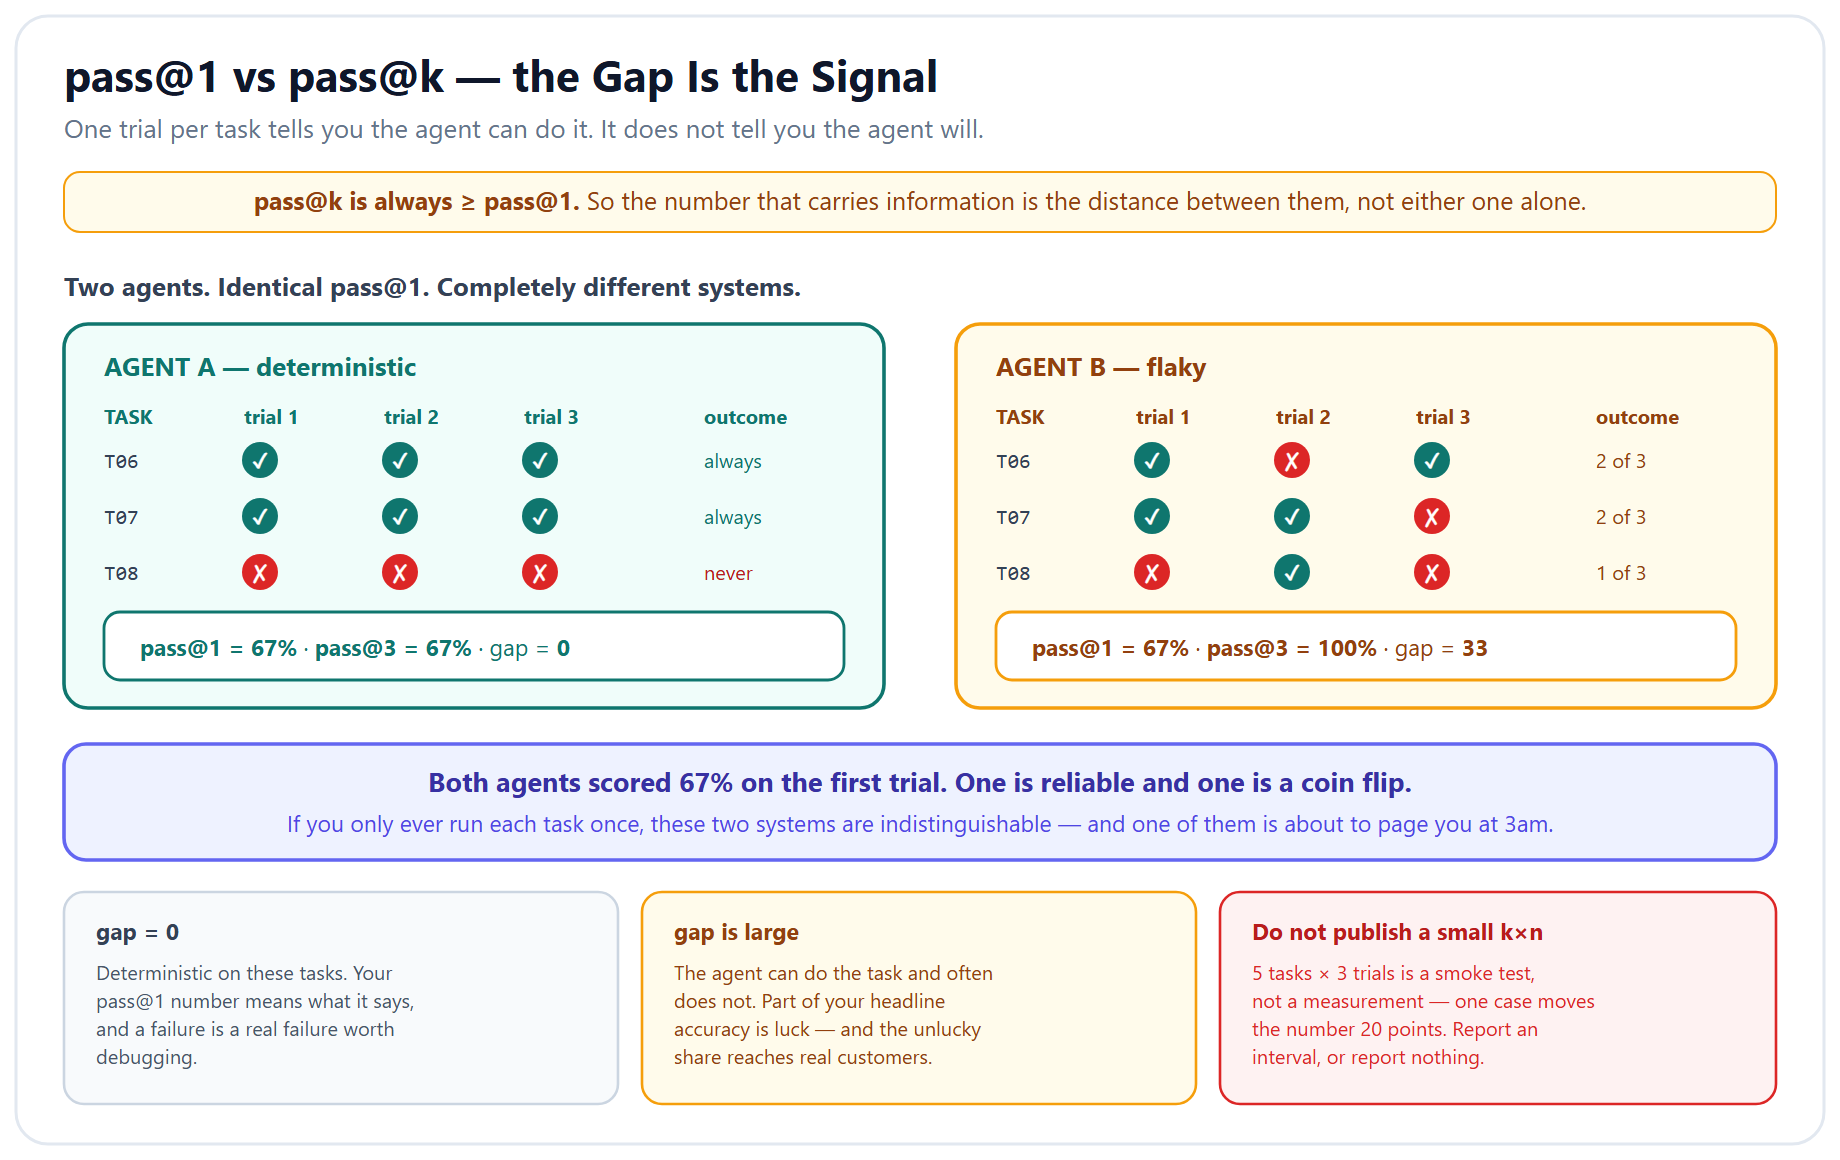

**Figure — The gap is the signal, not the numbers.** Running each task once tells you nothing about reliability: an agent that succeeds two times in three looks identical to a deterministic one when you only look at the first trial. `pass@k` is always ≥ `pass@1`, so the interesting quantity is the distance between them — that distance is how much of your headline accuracy is luck.

In [ ]:
# --- pass@k Demo (subset of 5 tests for speed) ---
trial_count = 3
# Pick the subset DELIBERATELY: every case that Grader 1 got wrong, topped up with cases
# it got right. Sampling only cases that already pass produces pass@1 == pass@k and a gap
# of zero, which demonstrates nothing — the gap IS the signal this section is about.
misrouted_cases = [case for case, record in zip(TEST_DATASET, routing_results)
                   if not record["correct"]]
correctly_routed = [case for case, record in zip(TEST_DATASET, routing_results)
                    if record["correct"]]
pass_at_k_subset = (misrouted_cases + correctly_routed)[:5]
print(f"subset: {[case['id'] for case in pass_at_k_subset]} "
      f"({len(misrouted_cases)} of them failed Grader 1)")

print(f"pass@{trial_count} Consistency Test (5 test cases x {trial_count} trials)")
print("=" * 60)

pass_at_1_count = 0
pass_at_k_count = 0

for test_case in pass_at_k_subset:
    trials = []
    for trial in range(trial_count):
        result = process_ticket(test_case)
        correct = evaluate_routing(test_case["expected_category"], result["category"])
        trials.append(correct)

    passed_first_try = trials[0]  # First try
    passed_any_trial = any(trials)  # At least 1 of K correct
    if passed_first_try: pass_at_1_count += 1
    if passed_any_trial: pass_at_k_count += 1

    first_mark = "\u2705" if passed_first_try else "\u274c"
    any_mark = "\u2705" if passed_any_trial else "\u274c"
    print(f"{test_case['id']}: trials={trials} | pass@1={first_mark} "
          f"| pass@{trial_count}={any_mark}")

print(f"\npass@1:  {pass_at_1_count}/{len(pass_at_k_subset)} "
      f"({pass_at_1_count/len(pass_at_k_subset)*100:.0f}%)")
print(f"pass@{trial_count}:  {pass_at_k_count}/{len(pass_at_k_subset)} "
      f"({pass_at_k_count/len(pass_at_k_subset)*100:.0f}%)")
print(f"\nInterpretation: pass@{trial_count} >= pass@1 always. The GAP is the signal —")
print(f"  gap of 0   -> the agent is deterministic on these queries")
print(f"  gap > 0    -> it sometimes gets there and sometimes does not, which means")
print(f"                your pass@1 number is partly luck")
print(f"\n⚠️  {len(pass_at_k_subset)} cases x {trial_count} trials is far too small to publish. With this many")
print(f"   samples a one-case difference moves the number by {100/len(pass_at_k_subset):.0f} points.")
print(f"   Section 10 shows how to say how uncertain a number like this actually is.")

## 9b. The Same Eval Suite, in OpenAI's Eval Framework

OpenAI ships a formal evaluation framework — JSONL datasets, YAML configs, model-graded evals run by the `oaieval` CLI. Here is the same eval suite expressed in its terms, and why this lab still builds its own.

| Concern | This lab | OpenAI Evals |
|---|---|---|
| **Dataset** | Python dicts in a cell | JSONL — one `{"input": …, "ideal": …}` per line |
| **Config** | Python: the graders are functions you can read | YAML: `id`, `metrics`, `grading_type` |
| **Grading** | Graders you wrote, plus a cross-family LLM judge | Model-graded, executed by `oaieval` |
| **Trajectory** | A substring grounding proxy, built in section 6 — this agent calls no tools | Not built in — you add it yourself |
| **Consistency** | `pass@k` over explicit trials (section 9) | Not built in |
| **Regression** | The before/after comparison you run in section 8 | Baseline run vs candidate run |
| **Reporting** | matplotlib, in the notebook | The hosted OpenAI Evals platform |

**Why this lab writes its own graders anyway.** Two of the three layers you built have no equivalent above: trajectory evaluation and `pass@k` are both things you would add by hand regardless. And a grader you did not write is a grader you cannot calibrate — section 10 measures this lab's judge against human labels, which is only possible because every scoring rule is visible Python. A hosted platform is a fine place to *run* an eval suite; it is a poor place to learn what the numbers mean.

Further reading — [Getting started with OpenAI Evals](https://developers.openai.com/cookbook/examples/evaluation/getting_started_with_openai_evals), [model-graded evals](https://developers.openai.com/cookbook/examples/evaluation/use_gpt4o_as_judge_for_model_graded_evals) and [regression detection](https://developers.openai.com/cookbook/examples/evaluation/use-cases/regression).

## The 3-Layer Eval Hierarchy — Summary

| Layer | What | How | Metric |
|-------|------|-----|--------|
| **Layer 1: LLM Eval** | Single-turn response quality | LLM-as-Judge with rubric | accuracy, completeness, helpfulness, tone (1-5) |
| **Layer 2: RAG Eval** | Retrieval + generation | Graders you write yourself | faithfulness, answer relevancy, recall@k (Lab 5.4) |
| **Layer 3: Agent Eval** | Multi-step trajectories | Tool tracking + pass@k | routing accuracy, F1, consistency |

## 10. Deep dive — your judge is a system under test too

*Self-paced. This is the most important section in the lab.*

Everything in sections 5, 7 and 8 rests on one assumption nobody checked: **that the judge is right.**

You built a grader, pointed it at your agent, drew a dashboard from its output, and used that dashboard to decide which category to improve. If the judge is systematically wrong, every one of those steps is wrong too — and confidently so, because the numbers look fine.

### The one rule you already applied

The judge in this notebook is `claude-haiku-4-5` while the agent is `gpt-4.1-mini`. That is not incidental. **Self-preference bias** means a judge over-rewards output from its own model family — same training data, same alignment, same house style, so the judge recognises its own idiom and scores it as quality. The easy mistake is to grade GPT output with a GPT judge.

> **The rule, now standing for the rest of the programme:** the judge never shares a model family with the system under test. Lab 5.1's quality curve depends on it, Lab 5.2 explains why, Lab 5.4 applies it to RAG graders.

The other four biases, so you recognise them when a number looks too good:

| Bias | What it does | Mitigation |
|---|---|---|
| **Position** | In pairwise comparison the first-shown answer wins ~10–15 points more often | Run both orderings and average |
| **Verbosity** | Longer answers score higher regardless of content | Score dimensions separately; length-control the rubric |
| **Format** | Markdown and structure read as quality | Normalise formatting before judging |
| **Calibration drift** | The scale moves as the model updates underneath you | Re-calibrate on a schedule; treat a judge swap as an eval migration, not a config change |

### What actually validates a judge: human labels

Bias controls reduce known errors. They do not tell you whether the judge agrees with *you* about what good looks like on *your* domain. Only labelled data does that.

The method is unglamorous and takes twenty minutes:

1. Take a sample of graded responses — 15 to 20 is enough to catch a badly broken judge.
2. Label them yourself, on the same scale, **without looking at the judge's score**.
3. Compare. Report agreement, and look at where you disagree.
4. Below ~80% agreement, **the grader is what needs fixing, not the agent.**

The cell below does the comparison. `HUMAN_LABELS` ships **empty on purpose** — filling it with invented scores would be a calibration against numbers nobody assigned. Run the cell and it prints a labelling worksheet; score those rows yourself, without looking at the judge, then paste them in.

> **Why this is the section that matters:** an evaluator is a system under test like any other, and it is the one system nobody thinks to test. Every framework you will ever use is sold as the thing you trust. This is how you find out whether you should.

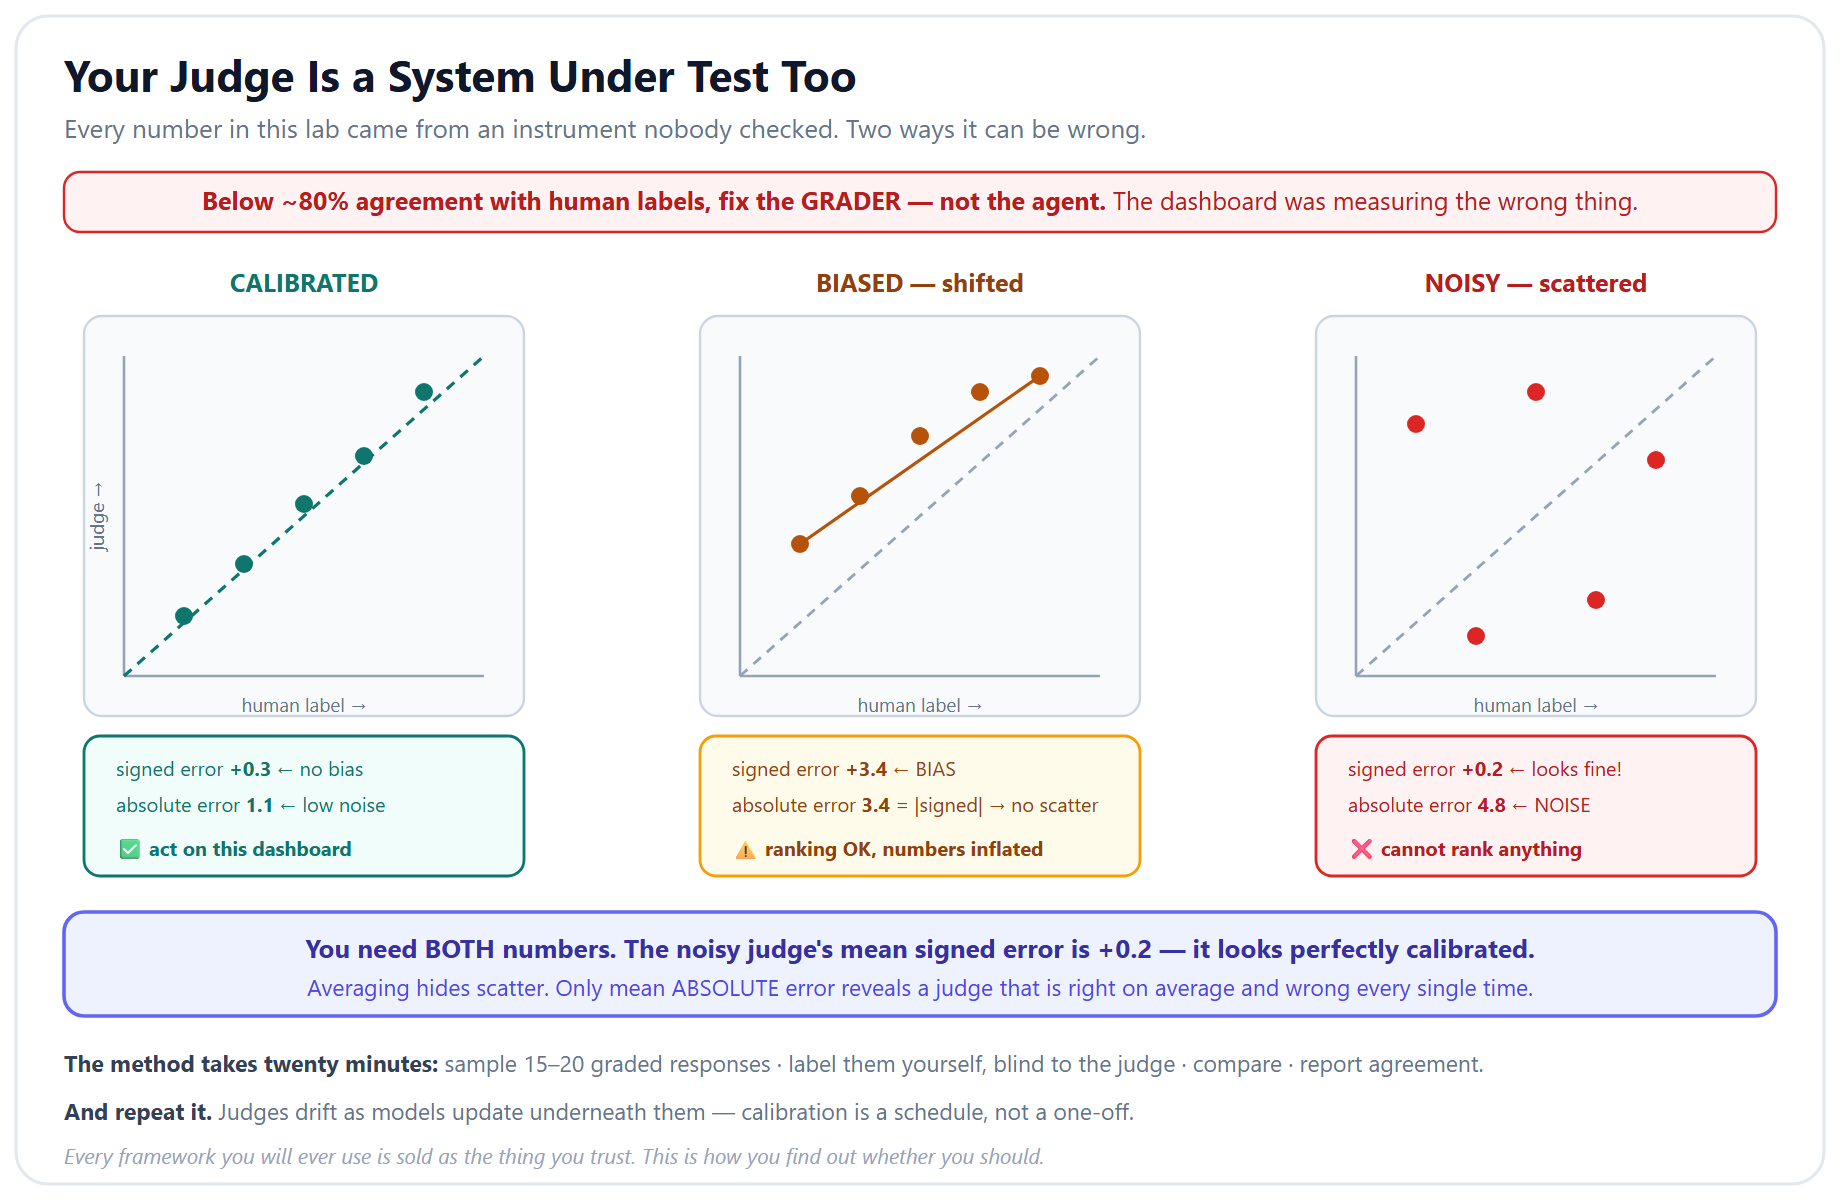

**Figure — Two failure modes a dashboard cannot show you.** A biased judge is shifted: it agrees on ranking but is consistently generous or harsh, so every absolute number is wrong in the same direction. A noisy judge is scattered: it is right on average and wrong on any given case, so it cannot rank two candidates. Mean signed error catches the first, mean absolute error the second — and you need both.

In [ ]:
# --- Calibrate the judge against human labels ---
# Replace HUMAN_LABELS with YOUR OWN judgements before trusting any of this. The point of the
# exercise is that these came from a person who did not see the judge's score first.

# Deliberately EMPTY. Shipping invented scores here would teach exactly the wrong lesson:
# a calibration run against numbers nobody assigned is a calibration of nothing.
#
# Fill this in yourself. Score each response out of 20 WITHOUT looking at the judge's answer
# first - that is the whole experiment. The worksheet below prints the cases to label.
HUMAN_LABELS = {
    # "TKT-00014": 17,
}

AGREEMENT_TOLERANCE = 3          # within this many points out of 20 counts as agreement


def compare_judge_with_humans(human_labels, tolerance=AGREEMENT_TOLERANCE):
    """Compare the judge's totals against human labels on the overlapping test cases.

    Args:
        human_labels: mapping of test id -> human total out of 20.
        tolerance: how many points apart two scores may be and still count as agreeing.

    Returns:
        A dict with the paired scores, the agreement rate, the mean signed error (the judge's
        bias direction) and the mean absolute error.
    """
    paired = []
    for position, test_case in enumerate(TEST_DATASET):
        judge_record = quality_results[position]
        human_score = human_labels.get(test_case["id"])
        if judge_record is None or human_score is None:
            continue                                  # unscored, or not labelled by a human
        paired.append({
            "id": test_case["id"],
            "human": human_score,
            "judge": judge_record["total"],
            "difference": judge_record["total"] - human_score,
        })

    if not paired:
        return {"paired": [], "agreement_rate": None,
                "mean_signed_error": None, "mean_absolute_error": None}

    agreed = sum(1 for comparison in paired
                 if abs(comparison["difference"]) <= tolerance)
    return {
        "paired": paired,
        "agreement_rate": agreed / len(paired) * 100,
        "mean_signed_error": statistics.fmean(
            comparison["difference"] for comparison in paired),
        "mean_absolute_error": statistics.fmean(
            abs(comparison["difference"]) for comparison in paired),
    }


if not HUMAN_LABELS:
    print("HUMAN_LABELS is empty — here is the worksheet. Score each one out of 20 before")
    print("you look at the judge's number, then paste your scores into HUMAN_LABELS above.")
    print("=" * 78)
    for test_case in TEST_DATASET[:10]:
        print(f'  "{test_case["id"]}":  __ / 20   [{test_case["expected_category"]}]  '
              f'{test_case["query"][:58]}')
    print("=" * 78)

calibration = compare_judge_with_humans(HUMAN_LABELS)

print()
print("JUDGE CALIBRATION — human label vs judge score")
print("=" * 62)
print(f"{'ID':<6} {'human':>7} {'judge':>7} {'diff':>7}   verdict")
print("-" * 62)
for comparison in calibration["paired"]:
    verdict = ("agrees" if abs(comparison["difference"]) <= AGREEMENT_TOLERANCE
               else "DISAGREES")
    print(f"{comparison['id']:<6} {comparison['human']:>5}/20 "
          f"{comparison['judge']:>5}/20 {comparison['difference']:>+7}   {verdict}")

print("\n" + "=" * 62)
if calibration["agreement_rate"] is None:
    print("No overlapping rows — label some cases and run this again.")
else:
    print(f"  Agreement (within ±{AGREEMENT_TOLERANCE} points): "
          f"{calibration['agreement_rate']:.0f}%")
    print(f"  Mean signed error (judge − human): "
          f"{calibration['mean_signed_error']:+.2f}  ← the judge's BIAS DIRECTION")
    print(f"  Mean absolute error:               "
          f"{calibration['mean_absolute_error']:.2f}  ← the judge's NOISE")

    if calibration["agreement_rate"] >= 80:
        print("\n  ✅ The judge tracks human opinion closely enough to act on.")
    else:
        print("\n  ❌ Below 80% agreement. Fix the GRADER before touching the agent —")
        print("     every conclusion in sections 7 and 8 was drawn from this instrument.")

    if calibration["mean_signed_error"] > 1.5:
        print("  ⚠️  Positive bias: the judge is more generous than you are. Everything")
        print("     on the dashboard is flattered by roughly this much.")
    elif calibration["mean_signed_error"] < -1.5:
        print("  ⚠️  Negative bias: the judge is harsher than you are. You may be chasing")
        print("     regressions that your customers would not notice.")

## 11. Deep dive — evals belong in CI, not in a notebook

*Self-paced.*

Here is the uncomfortable version of what you have built: **an eval suite you run by hand, after a change, when you remember to.** That is a demo. The business scenario at the top of this lab describes a prompt tweak that degraded billing accuracy by 35% and went unnoticed for three days — and nothing in sections 1–9 would have caught it any faster, because nothing in sections 1–9 runs automatically.

An eval suite becomes infrastructure at exactly one moment: **when it can block a merge.**

### The shape

| | Runs | Contains | Blocks the merge? |
|---|---|---|---|
| **On every pull request** | ~2 min | A fast subset — deterministic graders only, no LLM judge | Yes |
| **Nightly / on release** | ~30 min | The full suite, all three graders, `pass@k` | Yes, for release |
| **Continuously in production** | always | Sampled live traffic scored by the same graders | No — it alerts |

The split matters. Deterministic graders are free and instant, so they can gate every push. LLM-judged graders cost money and take minutes, so they run on a schedule. A team that puts the whole suite on every commit stops running it within a fortnight.

### Two things to get right

**Thresholds must be committed, not remembered.** `ROUTING_ACCURACY_FLOOR = 0.85` in a file that a reviewer can see is a decision. A number in someone's head is not.

**The eval suite has its own cost.** Twenty-four cases x three graders x one LLM judge is fine. The same suite on every commit, on a busy repo, is a bill nobody budgeted. Track it like any other CI cost.

LangSmith ships a **pytest integration** (SDK v0.3.0+) so eval scores gate a pull request exactly like a unit test. The cell below writes out a runnable `test_shopsmart_evals.py` and the GitHub Actions workflow that runs it — the two files that turn everything above into infrastructure.

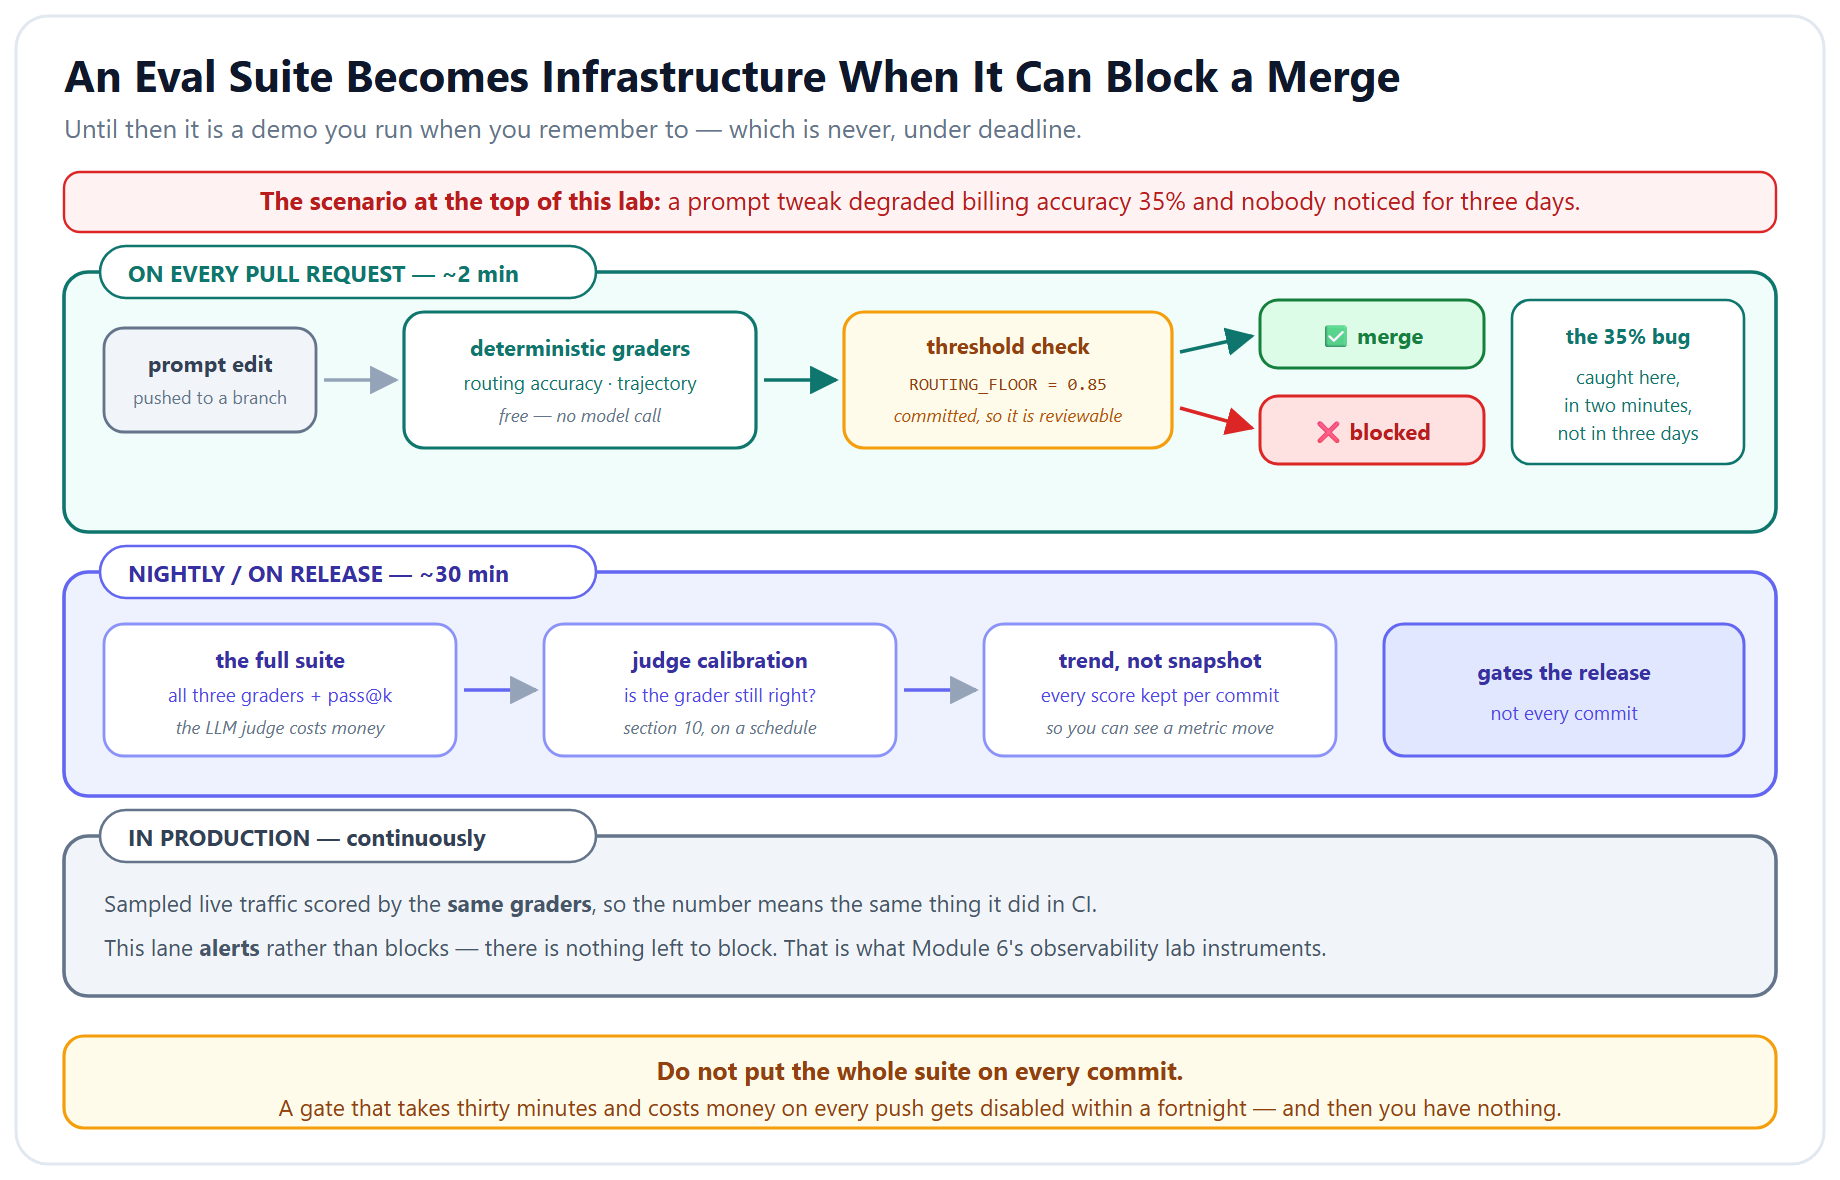

**Figure — Where each grader belongs in the loop.** The deterministic graders are free and fast, so they gate every pull request. The judged graders cost money and minutes, so they run nightly and gate the release. Production scoring alerts rather than blocks, because there is nothing left to block. Put the whole suite on every commit and the team disables it within a fortnight.

In [ ]:
# --- Write the two files that turn this notebook into a CI gate ---
# These are written to disk, not executed here. Copy them into your repo.
from pathlib import Path

PYTEST_FILE = '''"""Regression gate for the ShopSmart support agent.

Run locally:   pytest test_shopsmart_evals.py -v
Run in CI:     pytest test_shopsmart_evals.py -v -m "not slow"

The fast tests use deterministic graders only and cost nothing, so they gate every pull
request. The judged tests are marked `slow` and run nightly.
"""
import pytest

from shopsmart_agent import process_ticket          # your agent, imported not rebuilt
from shopsmart_evals import (TEST_DATASET, evaluate_routing, evaluate_quality,
                             evaluate_trajectory, evaluate_priority,
                             evaluate_tool_trajectory)

# Thresholds live in the repository, where a reviewer can see them change.
#
# FLOORS ARE SET FROM A MEASURED BASELINE, NOT FROM AMBITION. Pick them by running the suite,
# reading the numbers, and subtracting a margin for run-to-run variance. A floor above what
# your system does today is not a quality bar - it is a red build on day one, which teams
# route around by deleting the test.
#
# !!! THE NUMBERS BELOW ARE PLACEHOLDERS, NOT MEASUREMENTS. !!!
# They were sized for a simpler agent with no tools and no
# retriever. This agent calls ten tools and a FAISS index, so its scores are a different
# distribution entirely - these floors describe a system you are not running.
# Run sections 7 and 7c, read YOUR five numbers, and replace all five floors before committing.
# Leaving them is the exact failure this lab spends section 11 warning you about.
ROUTING_ACCURACY_FLOOR = 0.75     # PLACEHOLDER - re-derive from your run
PRIORITY_ACCURACY_FLOOR = 0.40    # PLACEHOLDER - priority is a 4-way call and usually weaker
TRAJECTORY_PASS_FLOOR = 0.40      # PLACEHOLDER - the contains-check proxy, see 6b
TOOL_TRAJECTORY_F1_FLOOR = 0.50   # PLACEHOLDER - recorded tool calls vs the reference, see 7c
QUALITY_TOTAL_FLOOR = 12          # PLACEHOLDER - out of 20


@pytest.fixture(scope="session")
def agent_outputs():
    """Run every task once and cache the transcripts for all graders in this session."""
    return {case["id"]: process_ticket(case) for case in TEST_DATASET}


def gradable_cases(agent_outputs):
    """Return the cases whose ANSWER came from the agent rather than from a human.

    Escalated tickets are handled by a manager - in this harness a fixed stub - so the
    quality and grounding graders would be scoring the stub rather than the agent.
    Routing and priority still apply to every case; only the content graders drop these.
    """
    return [case for case in TEST_DATASET
            if not agent_outputs[case["id"]].get("needs_escalation", False)]


def test_routing_accuracy_meets_floor(agent_outputs):
    """Deterministic, free, and fast enough to run on every push."""
    correct = sum(1 for case in TEST_DATASET
                  if evaluate_routing(case["expected_category"],
                                      agent_outputs[case["id"]]["category"]))
    accuracy = correct / len(TEST_DATASET)
    assert accuracy >= ROUTING_ACCURACY_FLOOR, (
        f"routing accuracy {accuracy:.0%} fell below the {ROUTING_ACCURACY_FLOOR:.0%} floor")


@pytest.mark.parametrize("case", TEST_DATASET, ids=lambda case: case["id"])
def test_each_case_routes_correctly(case, agent_outputs):
    """One test per task, so a failure names the case rather than a percentage."""
    actual = agent_outputs[case["id"]]["category"]
    assert actual == case["expected_category"], (
        f"{case['id']}: expected {case['expected_category']}, got {actual}")


def test_trajectory_pass_rate_meets_floor(agent_outputs):
    """Also deterministic — the contains-check needs no model."""
    cases = gradable_cases(agent_outputs)
    passed = sum(1 for case in cases
                 if evaluate_trajectory(agent_outputs[case["id"]]["final_response"],
                                        case["must_contain"])["pass"])
    pass_rate = passed / len(cases)
    assert pass_rate >= TRAJECTORY_PASS_FLOOR, (
        f"trajectory pass rate {pass_rate:.0%} fell below {TRAJECTORY_PASS_FLOOR:.0%}")


def test_priority_accuracy_meets_floor(agent_outputs):
    """The supervisor decides a priority as well as a category - grade both.

    Deterministic and free: tickets.json ships a priority label for every ticket.
    """
    correct = sum(1 for case in TEST_DATASET
                  if evaluate_priority(case["expected_priority"],
                                       agent_outputs[case["id"]]["priority"]))
    accuracy = correct / len(TEST_DATASET)
    assert accuracy >= PRIORITY_ACCURACY_FLOOR, (
        f"priority accuracy {accuracy:.0%} fell below the {PRIORITY_ACCURACY_FLOOR:.0%} floor")


def test_tool_trajectory_meets_floor(agent_outputs):
    """Grade what the agent DID, not only what it said.

    Compares the tool calls recorded in `tools_used` against the reference trajectory.
    Deterministic, free, and the only test here that can tell "wrong tool" from
    "right tool, bad answer".
    """
    scores = [evaluate_tool_trajectory(case["expected_tools"],
                                       agent_outputs[case["id"]]["tools_used"])["f1"]
              for case in TEST_DATASET]
    mean_f1 = sum(scores) / len(scores)
    assert mean_f1 >= TOOL_TRAJECTORY_F1_FLOOR, (
        f"mean tool-trajectory F1 {mean_f1:.2f} fell below {TOOL_TRAJECTORY_F1_FLOOR:.2f}")


@pytest.mark.slow
def test_response_quality_meets_floor(agent_outputs):
    """Judged, so it costs money and minutes. Nightly, not per-push."""
    scores = []
    for case in gradable_cases(agent_outputs):
        record = evaluate_quality(case["query"],
                                  agent_outputs[case["id"]]["final_response"], case["ideal"])
        if record is not None:                      # never let a judge failure pass as a score
            scores.append(record["total"])
    assert scores, "the judge failed on every case — the grader is broken, not the agent"
    average = sum(scores) / len(scores)
    assert average >= QUALITY_TOTAL_FLOOR, (
        f"average quality {average:.1f}/20 fell below the {QUALITY_TOTAL_FLOOR}/20 floor")
'''

WORKFLOW_FILE = '''name: agent-evals

on:
  pull_request:
  schedule:
    - cron: "0 2 * * *"          # nightly at 02:00 UTC

jobs:
  fast-gate:
    name: Deterministic graders (blocks the merge)
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.12"
      - run: pip install -r requirements.txt
      - name: Run the fast eval subset
        env:
          OPENAI_API_KEY: ${{ secrets.OPENAI_API_KEY }}
        run: pytest test_shopsmart_evals.py -v -m "not slow"

  full-suite:
    name: Full suite including the LLM judge
    if: github.event_name == 'schedule'
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.12"
      - run: pip install -r requirements.txt
      - name: Run every grader
        env:
          OPENAI_API_KEY: ${{ secrets.OPENAI_API_KEY }}
          ANTHROPIC_API_KEY: ${{ secrets.ANTHROPIC_API_KEY }}
        run: pytest test_shopsmart_evals.py -v
'''

Path("test_shopsmart_evals.py").write_text(PYTEST_FILE, encoding="utf-8")
Path(".github/workflows").mkdir(parents=True, exist_ok=True)
Path(".github/workflows/agent-evals.yml").write_text(WORKFLOW_FILE, encoding="utf-8")

print("Wrote two files:")
print("  test_shopsmart_evals.py           — the gate")
print("  .github/workflows/agent-evals.yml — what runs it")

What changes the moment those two files land in a repository:

- a prompt edit that breaks billing routing fails **the PR**, not a customer
- the thresholds are reviewable, so lowering one becomes a **visible decision** in a diff
- the expensive judged tests run nightly, so nobody disables the suite for being slow

That is the step that turns everything above from a demonstration into infrastructure.

## 12. From lab to production

*Self-paced.*

*Several of the rows below are the same problem in different clothes — cost accounting, structured failure records, versioned configuration, dataset versioning. Teams running more than one agent usually end up factoring those into a shared internal library rather than rebuilding them per service. This programme does not ship one; being able to name what would belong in it is the point.*

| Gap in this notebook | What production needs | Where it lands |
|---|---|---|
| The suite runs when you run it | A CI gate on every PR, full suite nightly | You, today (section 11) |
| The judge was never validated | Human-label calibration on a schedule, tracked over time | You, today (section 10) |
| 24 cases, generated from shipped labels | 100+ drawn from real traffic, versioned alongside the prompt | Your production stack |
| Trajectory grading is a keyword proxy | A real trajectory evaluator over recorded tool calls — see 6b | Your production stack |
| `pass@k` on 5 cases × 3 trials | Enough trials to report an interval, not a point | Your production stack |
| Eval cost is untracked | Tokens and spend per eval run — suites get expensive quietly | Your production stack |
| Results print to stdout | Persisted per commit, so you can see a metric move over time | Your production stack |
| Section 8 prints a workflow but changes nothing | An actual before/after: edit the prompt, re-run, compare | You, today |

**On that last row — it is worth being blunt.** Section 8 identifies the weakest category and then prints the steps you *would* take. It does not take them. That is the one place this lab describes the loop instead of closing it, and finishing it is the best exercise in the notebook: change the weakest handler's prompt, re-run sections 4–7, and put the two dashboards side by side.

**If you take one thing from this lab:** a number you cannot defend is worse than no number, because you will act on it. Section 10 is what makes the rest defensible.

## 13. Improving the numbers — what to change, and how to know it worked

*Self-paced. No new code — this is the reading you do **after** a run, and the discipline that
stops "it got better" from being wishful thinking.*

Your suite now produces three numbers. Three numbers are not a to-do list. This section turns them
into one.

### 13.1 First, read the diagnosis — do not reach for the prompt

Every instinct says "the scores are low, improve the prompt." Resist it for ten minutes. A low
score has four possible causes, and only one of them is fixed by prompting:

| Cause | How to recognise it | What to do |
|---|---|---|
| **The label is wrong** | You read the ticket and disagree with the shipped category | Fix the dataset, not the agent. Section 3 flags `TKT-00010` for exactly this |
| **The expectation is wrong** | The answer is good; the grader wanted a fact nobody asked for | Fix `build_expected_content`. A grader that penalises correct answers inverts every conclusion below it |
| **The grader is wrong** | The judge disagrees with you on cases you have labelled yourself | Recalibrate — section 10. An uncalibrated judge is a random number with a decimal point |
| **The agent is wrong** | Everything above checks out and the answer is still bad | *Now* change the agent |

**Work down that table in order.** Three of the four rows are cheaper to fix than the fourth, and
skipping them means tuning a prompt against a broken ruler.

### 13.2 Routing accuracy — the cheapest metric to move, and the least interesting

Routing is usually the healthiest of the three: a six-way classification with clear category
descriptions is an easy task for a modern model. When it does fail, it fails on **tickets that
legitimately belong to two categories at once** — a furious complaint that also mentions an order
is both `escalation` and `order_status`, and the label picks one.

In ascending order of cost:

| Change | What it fixes | Cost |
|---|---|---|
| **State precedence in the prompt** — "if a ticket qualifies for both `escalation` and a topic category, choose `escalation`" | Ambiguous tickets where two categories genuinely apply | One prompt line |
| **Add two or three few-shot examples**, taken from the cases you actually got wrong | The specific boundary the model keeps mis-drawing | A few lines, and a little latency |
| **Return a confidence score and route the low-confidence tail to a human** | Nothing — it *contains* the failure rather than fixing it | A prompt field plus a branch; PROJECT 2 already does this |
| **Fine-tune, or move to a stronger classifier model** | Systematic weakness across many categories | Real money, and almost never the right first move at this accuracy |

> **The confidence route is not cheating.** Routing accuracy of 96% on a support queue means one
> ticket in twenty-five reaches the wrong specialist. If the low-confidence cases are also the
> wrong ones, sending that slice to a human costs a fraction of the volume and removes the failure
> entirely. But check that confidence actually correlates with correctness before relying on it —
> frequently it does not, and a confident wrong answer is the whole problem.

### 13.3 Response quality — read the DIMENSIONS, not the total

This is where a total out of 20 actively hides the answer. Split it.

In the run that prompted this section, the four dimensions were nowhere near equal:

| Dimension | Average | Points lost across 24 cases |
|---|---|---|
| Tone | 4.79 / 5 | **5** |
| Accuracy | 3.96 / 5 | 25 |
| Helpfulness | 3.71 / 5 | 31 |
| **Completeness** | **3.21 / 5** | **43** |

Read the last column. **Tone is finished** — five points from perfect across the entire suite — so
every hour spent on "be more empathetic" is an hour spent on the one thing already solved. Over
40% of the total loss sits in a single dimension: **completeness**.

Completeness has a specific meaning here: *did the answer address every part of what was asked?*
It is the classic failure of a concise-instructed agent. The prompt says "3-5 sentences", the
customer asks two things, and the model answers the first one well and quietly drops the second.

What to try, cheapest first:

| Change | Why it targets completeness |
|---|---|
| **Remove or raise the length cap** | "3-5 sentences" is a completeness ceiling written into the prompt. Try "as long as it needs to be, and no longer" |
| **Enumerate the sub-questions** | Instruct the handler to identify every distinct question in the message and answer each one explicitly |
| **Give each handler a per-category checklist** | Returns: eligibility, process, timeframe, who pays return shipping. Billing: the amount, why it differs, what happens next |
| **Split into draft → review** | A second pass that asks only "did this answer everything?" — Lab 2.4's quality-gate pattern, applied here |

Then re-run and look at the dimension table again, not the total. If completeness rises while
accuracy falls, you have traded one for the other — longer answers have more room to be wrong —
and the total may barely move while the system has genuinely changed. **The total is the least
informative number the judge produces.**

### 13.4 Trajectory / grounding — the one that is actually bad

A pass rate near 50% looks alarming next to 96% routing. Before panicking, look at how the
failures distribute. In the same run:

| Category | Trajectory failures |
|---|---|
| `billing` | 0 / 4 |
| `order_status` | 0 / 4 |
| `escalation` | 2 / 4 |
| `technical` | 2 / 4 |
| `returns` | 3 / 4 |
| `product_inquiry` | 4 / 4 |

That is not a uniformly weak agent. **The two categories where the required token is a concrete
value looked up from the order record — an order ID, a status, a total — pass perfectly.** The
categories that fail are the ones where the required token is a *policy phrase* or a *product
attribute the customer did not explicitly ask about*.

So the diagnosis is precise: this agent reliably quotes the **record** it was handed and
unreliably quotes the **policy** it was handed. That is a much narrower problem than "grounding is
bad", and it has narrower fixes:

| Change | What it does | What it costs |
|---|---|---|
| **Name the required field in the handler prompt** — "always state the applicable return window" | Targets the misses directly, per category | One prompt line per handler |
| **Turn the policy into a checklist instead of a wall of prose** | Models skip prose; they rarely skip a numbered list they were told to cover | Rewriting the `policies.md` sections |
| **Retrieve the policy section instead of pasting all of it** | Shorter, more focused context — Lab 5.1's just-in-time retrieval, applied here | Real work, and a retriever to maintain |
| **Return structured output, then render it** | Makes the required field impossible to omit — it is a schema key | The answer starts to sound like a form |

> **Ask this before fixing any of it:** *should* a good answer contain that token at all? For the
> four `product_inquiry` cases the grader demanded the product's price, while the customers asked
> about warranty, compatibility, restock date and dimensions. The specialist prompt does instruct
> the agent to quote the amount, so the expectation is defensible — but defensible is not the same
> as useful, and an agent trained to recite prices nobody asked for is not obviously a better
> agent. **That is a design decision, not a bug, and it is yours to make.**

### 13.5 How to re-evaluate without fooling yourself

The measurement discipline matters more than any individual fix.

**1. Change one thing.** Two prompt edits and a model swap in one round produce a number you
cannot attribute. If it improves you will not know which change to keep; if it regresses you will
not know which to revert.

**2. Re-run the whole suite, not just the failing cases.** Re-running only the failures measures
whether you fixed them — never whether you broke something else. The category sitting at 100% is
exactly where a regression hides.

**3. Write the baseline down before you start.** All three headline numbers, the per-category
table, and the per-dimension split. "It feels better" is not a result. Section 11's CI gate exists
so this is recorded whether or not you remember to.

**4. The test set is not a training set.** Every time you read a failing case and edit the prompt
to fix that case, you move closer to a prompt tuned to these 24 tickets. The suite keeps rising
and the real queue does not. Two defences: keep a **held-out** slice you do not look at until you
believe you are finished, and periodically re-sample fresh cases — `tickets.json` has 100 and you
are using 24.

**5. Ask whether the change is larger than the noise.** At 24 cases, one case is **4 percentage
points**. A move from 54% to 58% is one ticket. That is not an improvement; it is a rounding error
wearing a result's clothing. Either gather more cases, or use `pass@k` (section 9) to find out how
much of your number is variance before you attribute any of it to your change.

**6. Re-calibrate the judge whenever you change the agent substantially.** Section 10 measured the
judge against human labels for one particular kind of answer. Make the answers longer, more
structured, more list-like, and that calibration may no longer hold. A judge that was accurate on
short prose is not automatically accurate on checklists.

**7. Fix the ruler before the thing being measured — and say which you did.** If a round's work was
repairing a wrong expectation or a miscalibrated judge, record that. The agent's score will move
and the agent will not have changed, and six months later somebody will try to reproduce the jump.

### 13.6 The order to work in

1. **Audit the labels and expectations** on every failing case. Cheapest, and it changes what
   every other number means.
2. **Re-calibrate the judge**, if quality is the metric you care about.
3. **Fix grounding** — the per-category prompt changes in 13.4. Largest headroom.
4. **Fix completeness** — the single dimension holding the quality total down.
5. **Contain routing** with a confidence threshold rather than chasing the last percent.
6. **Re-run everything, compare against the written baseline, and check the noise floor.**

Nothing on that list is a model upgrade. Reach for a bigger model once you have exhausted it — and
when you do, re-run the whole suite, because a stronger model changes *which* cases fail, not just
how many.

## Conclusion

In this lab we built a **3-layer evaluation suite** for ShopSmart's support agent:
- **Grader 1 (Routing):** Deterministic exact-match — did the agent route correctly?
- **Grader 2 (Quality):** LLM-as-Judge with 4-dimension rubric — is the response good?
- **Grader 3 (Trajectory):** Keyword contains-check — did the response use the right data?
- **Dashboard:** 4-panel Matplotlib visualization of all metrics
- **Eval-driven improvement:** Identify weakest category → improve → re-evaluate
- **pass@k:** Measure consistency across multiple trials

### Next Lab Preview
In **Lab 5.4** we take on **Layer 2 (RAG Eval)** against PROJECT 1's Financial Analyst RAG — implementing the metrics ourselves rather than importing a framework. Four deterministic retrieval metrics (`recall@k`, `precision@k`, `MRR`, `nDCG@k`) plus two judge-backed generation metrics, with the judge validated against human labels exactly as in section 10 here.